# SIMPOD — Fresh Final Model Comparison

Clean Kaggle notebook for:

- **Model A:** Flat Space-Group classifier
- **Model B:** 3-head multi-task classifier (Crystal System + Bravais Lattice + Space Group)
- **Model C:** 3-head classifier + crystallographic consistency loss

Final metrics:
**SG Top-1, SG Top-5, SG Macro-F1, CS Accuracy, BL Accuracy, Hierarchy Violation Rate.**

For the final paper table, run all three models in this notebook so that the split and evaluation protocol are identical.


In [11]:
import os, sys, json, glob, hashlib, subprocess, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

import tensorflow as tf
from tensorflow.keras import layers, Model

SEED = 42
IMG_SIZE = 104
BATCH_SIZE = 64
EPOCHS = 60
MIN_SG_FOR_EVAL = 20

CS_LOSS_WEIGHT = 0.25
BL_LOSS_WEIGHT = 0.25
SG_LOSS_WEIGHT = 1.00
LAMBDA_CONSISTENCY = 0.50

RUN_MODEL_A = True
RUN_MODEL_B = True
RUN_MODEL_C = True

WORK = Path("/kaggle/input/datasets/manjeetps/datasetsimpod/dataset")
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow:", tf.__version__)
print("GPU:", gpus)

if gpus:
    try:
        tf.keras.mixed_precision.set_global_policy("mixed_float16")
        print("Mixed precision enabled")
    except Exception as e:
        print(e)


TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Mixed precision enabled


## 1. Build/load the full labelled master table


In [12]:
from pathlib import Path

WORK = Path("/kaggle/working")
WORK.mkdir(parents=True, exist_ok=True)

print("Output directory:", WORK)

Output directory: /kaggle/working


In [14]:
master_df.to_csv(
    "/kaggle/working/SIMPOD_MASTER_FULL_LABELLED.csv",
    index=False
)

print("✅ Master dataframe saved to /kaggle/working/")

NameError: name 'master_df' is not defined

In [15]:
def get_crystal_system(sg):
    sg=int(sg)
    if 1 <= sg <= 2: return "Triclinic"
    if 3 <= sg <= 15: return "Monoclinic"
    if 16 <= sg <= 74: return "Orthorhombic"
    if 75 <= sg <= 142: return "Tetragonal"
    if 143 <= sg <= 167: return "Trigonal"
    if 168 <= sg <= 194: return "Hexagonal"
    if 195 <= sg <= 230: return "Cubic"
    return None

try:
    import spglib
except ImportError:
    subprocess.check_call([sys.executable,"-m","pip","install","-q","spglib"])
    import spglib

sg_to_symbol={}
for hall in range(1,531):
    info=spglib.get_spacegroup_type(hall)
    if info is None: continue
    try:
        n=int(info.number); sym=str(info.international_short)
    except Exception:
        n=int(info["number"]); sym=str(info["international_short"])
    sg_to_symbol.setdefault(n,sym)

def get_bravais14(sg):
    sg=int(sg)
    cs=get_crystal_system(sg)
    sym=sg_to_symbol.get(sg)
    if sym is None: return None
    c=sym.strip()[0].upper()

    if cs=="Triclinic": return "aP"
    if cs=="Monoclinic":
        if c=="P": return "mP"
        if c in "ABC": return "mC"
    if cs=="Orthorhombic":
        if c=="P": return "oP"
        if c in "ABC": return "oC"
        if c=="I": return "oI"
        if c=="F": return "oF"
    if cs=="Tetragonal":
        if c=="P": return "tP"
        if c=="I": return "tI"
    if cs=="Trigonal":
        if c=="R": return "hR"
        if c=="P": return "hP"
    if cs=="Hexagonal": return "hP"
    if cs=="Cubic":
        if c=="P": return "cP"
        if c=="I": return "cI"
        if c=="F": return "cF"
    return None

master_files=glob.glob("/kaggle/input/**/SIMPOD_MASTER_FULL_LABELLED.csv",recursive=True)

if master_files:
    master_df=pd.read_csv(master_files[0])
    print("Loaded:",master_files[0])
else:
    print("Rebuilding master table...")
    json_files=glob.glob("/kaggle/input/**/*.json",recursive=True)

    def find_sg(obj):
        keys={"space_group","spacegroup","space_group_number","spacegroup_number","sg_number","sg"}
        if isinstance(obj,dict):
            for k,v in obj.items():
                ck=str(k).lower().replace(" ","_").replace("-","_")
                if ck in keys: return v
            for v in obj.values():
                z=find_sg(v)
                if z is not None: return z
        elif isinstance(obj,list):
            for v in obj:
                z=find_sg(v)
                if z is not None: return z
        return None

    from tqdm.auto import tqdm
    rec=[]
    for jp in tqdm(json_files):
        ip=os.path.splitext(jp)[0]+".png"
        if not os.path.exists(ip): continue
        try:
            with open(jp,"r") as f: obj=json.load(f)
            sg=find_sg(obj)
            if sg is None: continue
            sg=int(float(sg))
            if 1 <= sg <= 230:
                rec.append({"json_path":jp,"image_path":ip,"space_group":sg})
        except Exception:
            pass
    master_df=pd.DataFrame(rec)

if "crystal_system" not in master_df:
    master_df["crystal_system"]=master_df["space_group"].apply(get_crystal_system)
if "bravais_lattice" not in master_df:
    master_df["bravais_lattice"]=master_df["space_group"].apply(get_bravais14)

master_df=master_df.dropna(subset=["crystal_system","bravais_lattice"]).reset_index(drop=True)

print("Samples:",len(master_df))
print("CS:",master_df["crystal_system"].nunique())
print("BL:",master_df["bravais_lattice"].nunique())
print("SG:",master_df["space_group"].nunique())
print("Missing SG:",sorted(set(range(1,231))-set(master_df["space_group"].unique())))

master_df.to_csv(WORK/"SIMPOD_MASTER_FULL_LABELLED.csv",index=False)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 962.5/962.5 kB 14.7 MB/s eta 0:00:00
Rebuilding master table...


  0%|          | 0/53258 [00:00<?, ?it/s]

Samples: 53258
CS: 7
BL: 14
SG: 225
Missing SG: [24, 89, 168, 207, 208]


## 2. Fixed rare-SG-aware train/validation/test split


In [16]:
sg_counts=master_df["space_group"].value_counts()
common_sg=sg_counts[sg_counts>=MIN_SG_FOR_EVAL].index
rare_sg=sg_counts[sg_counts<MIN_SG_FOR_EVAL].index

common_df=master_df[master_df["space_group"].isin(common_sg)].copy()
rare_df=master_df[master_df["space_group"].isin(rare_sg)].copy()

common_train,common_temp=train_test_split(
    common_df,test_size=0.30,random_state=SEED,stratify=common_df["space_group"]
)
common_val,common_test=train_test_split(
    common_temp,test_size=0.50,random_state=SEED,stratify=common_temp["space_group"]
)

train_df=pd.concat([common_train,rare_df],ignore_index=True).sample(
    frac=1,random_state=SEED
).reset_index(drop=True)
val_df=common_val.reset_index(drop=True)
test_df=common_test.reset_index(drop=True)

assert not (set(train_df.image_path)&set(val_df.image_path))
assert not (set(train_df.image_path)&set(test_df.image_path))
assert not (set(val_df.image_path)&set(test_df.image_path))

print("Common SG:",len(common_sg),"Rare SG:",len(rare_sg))
print("Train/Val/Test:",len(train_df),len(val_df),len(test_df))
print("Evaluated SG:",test_df.space_group.nunique())

def fp(series):
    s="\n".join(sorted(series.astype(str))).encode()
    return hashlib.sha256(s).hexdigest()

fingerprint={"train":fp(train_df.image_path),"val":fp(val_df.image_path),"test":fp(test_df.image_path)}
print(fingerprint)
with open(WORK/"split_fingerprint.json","w") as f: json.dump(fingerprint,f,indent=2)


Common SG: 141 Rare SG: 84
Train/Val/Test: 37525 7866 7867
Evaluated SG: 141
{'train': 'd8785b270ee979c9d2b8f359a11dd339da86ab9a76401081a7b28eb6b83d77c8', 'val': '16293b6c6b2dc26ef5d0d99c324c0121c3f84df6496fbbc501d81a5b41a61d93', 'test': '605de679d824e6be10bf20b48e5ffa83e646ad1ad3a831769a1c4387926abfa6'}


## 3. Label encoding


In [17]:
crystal_classes=sorted(master_df.crystal_system.unique())
bravais_classes=sorted(master_df.bravais_lattice.unique())
sg_classes=sorted(master_df.space_group.unique())

crystal_to_id={x:i for i,x in enumerate(crystal_classes)}
bravais_to_id={x:i for i,x in enumerate(bravais_classes)}
sg_to_id={int(x):i for i,x in enumerate(sg_classes)}
id_to_sg={i:int(x) for x,i in sg_to_id.items()}

N_CS=len(crystal_classes); N_BL=len(bravais_classes); N_SG=len(sg_classes)
assert N_CS==7 and N_BL==14

def encode(df):
    df=df.copy()
    df["crystal_id"]=df.crystal_system.map(crystal_to_id).astype("int32")
    df["bravais_id"]=df.bravais_lattice.map(bravais_to_id).astype("int32")
    df["sg_id"]=df.space_group.map(sg_to_id).astype("int32")
    return df

train_df=encode(train_df); val_df=encode(val_df); test_df=encode(test_df)

train_df.to_csv(WORK/"SIMPOD_FULL_TRAIN_ENCODED.csv",index=False)
val_df.to_csv(WORK/"SIMPOD_FULL_VAL_ENCODED.csv",index=False)
test_df.to_csv(WORK/"SIMPOD_FULL_TEST_ENCODED.csv",index=False)

print(N_CS,N_BL,N_SG)


7 14 225


## 4. TensorFlow data pipeline


In [18]:
AUTOTUNE=tf.data.AUTOTUNE

def load_sample(path,cs,bl,sg):
    im=tf.io.read_file(path)
    im=tf.io.decode_png(im,channels=1)
    im=tf.image.resize(im,[IMG_SIZE,IMG_SIZE])
    im=tf.cast(im,tf.float32)/255.0
    return im,(tf.cast(cs,tf.int32),tf.cast(bl,tf.int32),tf.cast(sg,tf.int32))

def make_ds(df,training=False):
    ds=tf.data.Dataset.from_tensor_slices((
        df.image_path.astype(str).values,
        df.crystal_id.astype("int32").values,
        df.bravais_id.astype("int32").values,
        df.sg_id.astype("int32").values
    ))
    if training:
        ds=ds.shuffle(min(len(df),10000),seed=SEED,reshuffle_each_iteration=True)
    ds=ds.map(load_sample,num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds=make_ds(train_df,True)
val_ds=make_ds(val_df,False)
test_ds=make_ds(test_df,False)

for x,y in train_ds.take(1):
    print(x.shape,[z.shape for z in y],float(tf.reduce_min(x)),float(tf.reduce_max(x)))


I0000 00:00:1788199328.012776      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1788199328.015964      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


(64, 104, 104, 1) [TensorShape([64]), TensorShape([64]), TensorShape([64])] 0.0 0.7169225215911865


## 5. Weighted losses and common backbone


In [20]:
def sqrt_weights(y,n):
    counts=np.bincount(np.asarray(y,dtype=int),minlength=n)
    w=np.sqrt(len(y)/(n*np.maximum(counts,1)))
    w=np.clip(w,0.5,4.0)
    w=w/w.mean()
    return w.astype("float32")

cs_w=sqrt_weights(train_df.crystal_id,N_CS)
bl_w=sqrt_weights(train_df.bravais_id,N_BL)
sg_w=sqrt_weights(train_df.sg_id,N_SG)

def weighted_ce(w):
    wt=tf.constant(w,dtype=tf.float32)
    def loss(y_true,y_pred):
        y_true=tf.cast(tf.reshape(y_true,[-1]),tf.int32)
        ce=tf.keras.losses.sparse_categorical_crossentropy(y_true,y_pred)
        return ce*tf.gather(wt,y_true)
    return loss

cs_loss=weighted_ce(cs_w)
bl_loss=weighted_ce(bl_w)
sg_loss=weighted_ce(sg_w)

def reset_seed():
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

def backbone():
    inp=layers.Input((IMG_SIZE,IMG_SIZE,1))
    x=layers.Conv2D(32,3,padding="same",activation="relu")(inp); x=layers.MaxPooling2D()(x)
    x=layers.Conv2D(64,3,padding="same",activation="relu")(x); x=layers.MaxPooling2D()(x)
    x=layers.Conv2D(128,3,padding="same",activation="relu")(x); x=layers.MaxPooling2D()(x)
    x=layers.Conv2D(256,3,padding="same",activation="relu")(x)
    x=layers.GlobalAveragePooling2D()(x)
    x=layers.Dense(256,activation="relu")(x)
    x=layers.Dropout(0.30)(x)
    return Model(inp,x,name="shared_backbone")


## 6. Evaluation helpers


In [21]:
Y_CS=test_df.crystal_id.to_numpy(int)
Y_BL=test_df.bravais_id.to_numpy(int)
Y_SG=test_df.sg_id.to_numpy(int)

SG_TO_CS=np.array([crystal_to_id[get_crystal_system(id_to_sg[i])] for i in range(N_SG)],int)
SG_TO_BL=np.array([bravais_to_id[get_bravais14(id_to_sg[i])] for i in range(N_SG)],int)

def top5(y,p):
    ids=np.argpartition(p,-5,axis=1)[:,-5:]
    return np.mean(np.any(ids==y[:,None],axis=1))

def sg_scores(p):
    pred=np.argmax(p,axis=1)
    labels=sorted(np.unique(Y_SG))
    return pred,accuracy_score(Y_SG,pred),top5(Y_SG,p),f1_score(
        Y_SG,pred,labels=labels,average="macro",zero_division=0
    )

def eval_A(model):
    p=model.predict(test_sg_ds,verbose=1)
    pred,top1,t5,mf1=sg_scores(p)
    pcs=SG_TO_CS[pred]; pbl=SG_TO_BL[pred]
    row={
        "Model":"A. Flat SG","SG Top-1":top1,"SG Top-5":t5,"SG Macro-F1":mf1,
        "CS Acc.":accuracy_score(Y_CS,pcs),"BL Acc.":accuracy_score(Y_BL,pbl),
        "Hierarchy violation":np.nan
    }
    return row,{"sg_probs":p,"pred_sg":pred,"pred_cs":pcs,"pred_bl":pbl}

def eval_3head(model,name):
    pcs_p,pbl_p,psg_p=model.predict(test_ds,verbose=1)
    psg,top1,t5,mf1=sg_scores(psg_p)
    pcs=np.argmax(pcs_p,axis=1); pbl=np.argmax(pbl_p,axis=1)
    implied_cs=SG_TO_CS[psg]; implied_bl=SG_TO_BL[psg]
    viol=np.mean((pcs!=implied_cs)|(pbl!=implied_bl))
    row={
        "Model":name,"SG Top-1":top1,"SG Top-5":t5,"SG Macro-F1":mf1,
        "CS Acc.":accuracy_score(Y_CS,pcs),"BL Acc.":accuracy_score(Y_BL,pbl),
        "Hierarchy violation":viol
    }
    return row,{"cs_probs":pcs_p,"bl_probs":pbl_p,"sg_probs":psg_p,
                "pred_cs":pcs,"pred_bl":pbl,"pred_sg":psg}

def callbacks(prefix):
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss",mode="min",patience=10,
                                         restore_best_weights=True,verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss",mode="min",factor=0.5,
                                             patience=4,min_lr=1e-6,verbose=1),
        tf.keras.callbacks.ModelCheckpoint(
            str(WORK/f"{prefix}_best.weights.h5"),monitor="val_loss",mode="min",
            save_best_only=True,save_weights_only=True,verbose=1)
    ]

def save_history(hist,prefix):
    df=pd.DataFrame(hist.history)
    df.to_csv(WORK/f"{prefix}_history.csv",index=False)
    return df

def plot_loss(df,prefix,title):
    plt.figure(figsize=(8,5))
    plt.plot(df.loss,label="Train")
    plt.plot(df.val_loss,label="Validation")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title(title)
    plt.legend(); plt.grid(alpha=.2); plt.tight_layout()
    plt.savefig(WORK/f"{prefix}_loss.png",dpi=300,bbox_inches="tight")
    plt.show()


## 7. Model A — Flat SG
Run this again if you want the **missing SG Top-5** and a completely fair A/B/C table in this fresh notebook.


Epoch 1/60
587/587 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.2208 - loss: 1.4381 - top5: 0.5500
Epoch 1: val_loss improved from None to 1.10690, saving model to /kaggle/working/model_A_best.weights.h5

Epoch 1: finished saving model to /kaggle/working/model_A_best.weights.h5
587/587 ━━━━━━━━━━━━━━━━━━━━ 60s 94ms/step - accuracy: 0.2229 - loss: 1.3572 - top5: 0.5865 - val_accuracy: 0.2516 - val_loss: 1.1069 - val_top5: 0.6439 - learning_rate: 3.0000e-04
Epoch 2/60
586/587 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.2353 - loss: 1.2798 - top5: 0.6239
Epoch 2: val_loss improved from 1.10690 to 1.09530, saving model to /kaggle/working/model_A_best.weights.h5

Epoch 2: finished saving model to /kaggle/working/model_A_best.weights.h5
587/587 ━━━━━━━━━━━━━━━━━━━━ 42s 71ms/step - accuracy: 0.2376 - loss: 1.2716 - top5: 0.6252 - val_accuracy: 0.2516 - val_loss: 1.0953 - val_top5: 0.6451 - learning_rate: 3.0000e-04
Epoch 3/60
586/587 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.2398

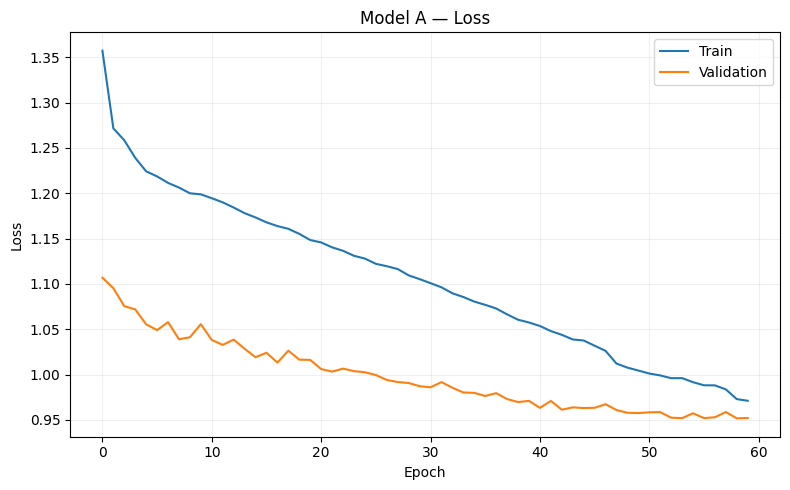

123/123 ━━━━━━━━━━━━━━━━━━━━ 10s 72ms/step
{'Model': 'A. Flat SG', 'SG Top-1': 0.31524087962374475, 'SG Top-5': np.float64(0.7120884708275073), 'SG Macro-F1': 0.09493714895058435, 'CS Acc.': 0.5008262361764332, 'BL Acc.': 0.40371170713105375, 'Hierarchy violation': nan}


In [32]:
def only_sg(x,y): return x,y[2]
train_sg_ds=train_ds.map(only_sg,num_parallel_calls=AUTOTUNE)
val_sg_ds=val_ds.map(only_sg,num_parallel_calls=AUTOTUNE)
test_sg_ds=test_ds.map(only_sg,num_parallel_calls=AUTOTUNE)

A_row=A_det=None

if RUN_MODEL_A:
    reset_seed()
    bb=backbone()
    inp=layers.Input((IMG_SIZE,IMG_SIZE,1))
    feat=bb(inp)
    sg=layers.Dense(N_SG,activation="softmax",dtype="float32",name="space_group")(feat)
    model_A=Model(inp,sg,name="Model_A_Flat_SG")
    model_A.compile(
        optimizer=tf.keras.optimizers.Adam(3e-4),
        loss=sg_loss,
        metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
                 tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5,name="top5")]
    )
    hA=model_A.fit(train_sg_ds,validation_data=val_sg_ds,epochs=EPOCHS,
                   callbacks=callbacks("model_A"),verbose=1)
    dA=save_history(hA,"model_A"); plot_loss(dA,"model_A","Model A — Loss")
    A_row,A_det=eval_A(model_A)
    print(A_row)


## 8. Model B — 3-head multi-task


Epoch 1/60
587/587 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - bravais_lattice_accuracy: 0.2238 - bravais_lattice_loss: 1.3135 - crystal_system_accuracy: 0.3117 - crystal_system_loss: 1.3064 - loss: 2.0918 - space_group_accuracy: 0.2145 - space_group_loss: 1.4369 - space_group_top5: 0.5308
Epoch 1: val_loss improved from None to 1.65710, saving model to /kaggle/working/model_B_best.weights.h5

Epoch 1: finished saving model to /kaggle/working/model_B_best.weights.h5
587/587 ━━━━━━━━━━━━━━━━━━━━ 54s 81ms/step - bravais_lattice_accuracy: 0.2613 - bravais_lattice_loss: 1.2337 - crystal_system_accuracy: 0.3494 - crystal_system_loss: 1.2127 - loss: 1.9517 - space_group_accuracy: 0.2272 - space_group_loss: 1.3407 - space_group_top5: 0.5898 - val_bravais_lattice_accuracy: 0.3416 - val_bravais_lattice_loss: 1.1265 - val_crystal_system_accuracy: 0.4368 - val_crystal_system_loss: 1.0935 - val_loss: 1.6571 - val_space_group_accuracy: 0.2499 - val_space_group_loss: 1.1020 - val_space_group_top5: 0.6426 - 

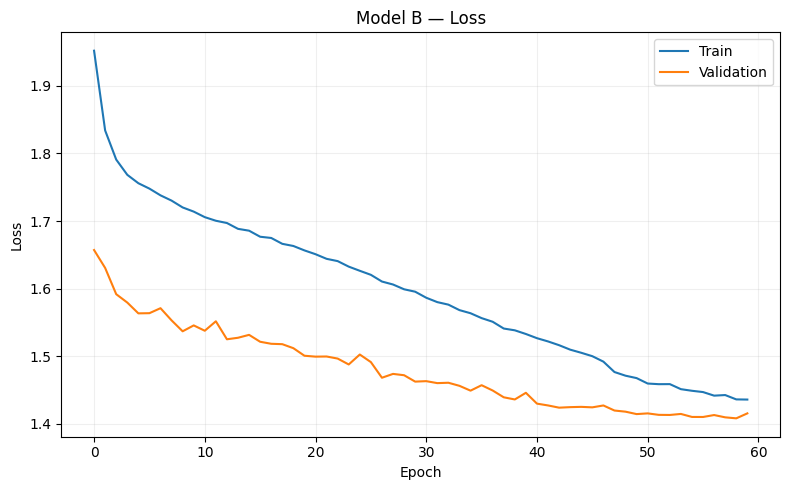

123/123 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step
{'Model': 'B. 3-head multi-task', 'SG Top-1': 0.31816448455573915, 'SG Top-5': np.float64(0.718062793949409), 'SG Macro-F1': 0.10327106506470703, 'CS Acc.': 0.516206940383882, 'BL Acc.': 0.4030761408414898, 'Hierarchy violation': np.float64(0.3011313079954239)}


In [33]:
B_row=B_det=None

if RUN_MODEL_B:
    reset_seed()
    bb=backbone()
    inp=layers.Input((IMG_SIZE,IMG_SIZE,1))
    f=bb(inp)
    cs=layers.Dense(N_CS,activation="softmax",dtype="float32",name="crystal_system")(f)
    bl=layers.Dense(N_BL,activation="softmax",dtype="float32",name="bravais_lattice")(f)
    sg=layers.Dense(N_SG,activation="softmax",dtype="float32",name="space_group")(f)
    model_B=Model(inp,[cs,bl,sg],name="Model_B_3head")
    model_B.compile(
        optimizer=tf.keras.optimizers.Adam(3e-4),
        loss=[cs_loss,bl_loss,sg_loss],
        loss_weights=[CS_LOSS_WEIGHT,BL_LOSS_WEIGHT,SG_LOSS_WEIGHT],
        metrics=[
            [tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
            [tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
            [tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
             tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5,name="top5")]
        ]
    )
    hB=model_B.fit(train_ds,validation_data=val_ds,epochs=EPOCHS,
                   callbacks=callbacks("model_B"),verbose=1)
    dB=save_history(hB,"model_B"); plot_loss(dB,"model_B","Model B — Loss")
    B_row,B_det=eval_3head(model_B,"B. 3-head multi-task")
    print(B_row)


## 9. Model C — 3-head + probabilistic crystallographic consistency


Epoch 1/60
  3/587 ━━━━━━━━━━━━━━━━━━━━ 22s 39ms/step - accuracy: 0.1580 - accuracy_1: 0.1328 - accuracy_2: 0.0217 - loss: 2.5044 - loss_loss: 1.7261 - top5: 0.0703  

I0000 00:00:1788199379.517490     144 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


587/587 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.3122 - accuracy_1: 0.2292 - accuracy_2: 0.2097 - loss: 2.1252 - loss_loss: 1.4357 - top5: 0.5219
Epoch 1: val_loss improved from None to 1.65325, saving model to /kaggle/working/model_C_best.weights.h5

Epoch 1: finished saving model to /kaggle/working/model_C_best.weights.h5
587/587 ━━━━━━━━━━━━━━━━━━━━ 97s 151ms/step - accuracy: 0.3679 - accuracy_1: 0.2737 - accuracy_2: 0.2214 - loss: 1.9845 - loss_loss: 1.3452 - top5: 0.5814 - val_accuracy: 0.4404 - val_accuracy_1: 0.3375 - val_accuracy_2: 0.2474 - val_loss: 1.6533 - val_loss_loss: 1.0970 - val_top5: 0.6421 - learning_rate: 3.0000e-04
Epoch 2/60
586/587 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.4201 - accuracy_1: 0.3206 - accuracy_2: 0.2357 - loss: 1.8292 - loss_loss: 1.2518 - top5: 0.6329
Epoch 2: val_loss improved from 1.65325 to 1.63501, saving model to /kaggle/working/model_C_best.weights.h5

Epoch 2: finished saving model to /kaggle/working/model_C_best.weights.h5
5

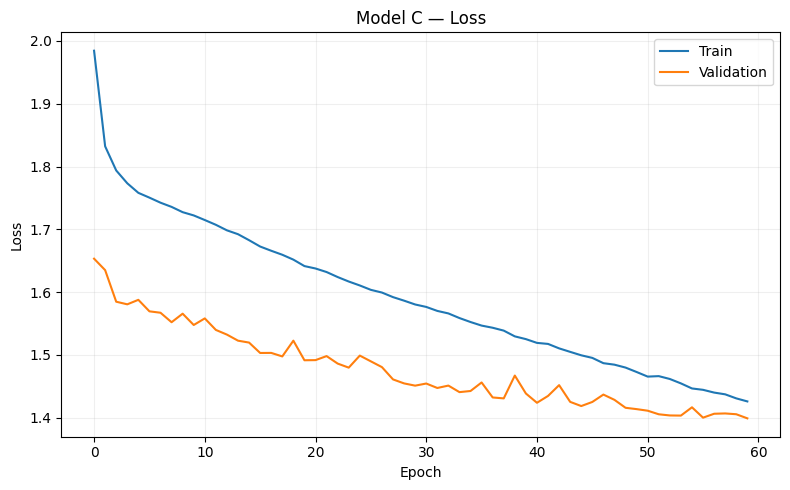

123/123 ━━━━━━━━━━━━━━━━━━━━ 20s 154ms/step
{'Model': 'C. 3-head + consistency', 'SG Top-1': 0.32477437396720477, 'SG Top-5': np.float64(0.7185712469810601), 'SG Macro-F1': 0.11428440896761057, 'CS Acc.': 0.518113639252574, 'BL Acc.': 0.4121011821532986, 'Hierarchy violation': np.float64(0.2966823439684759)}


In [22]:
M_CS=np.zeros((N_SG,N_CS),dtype="float32")
M_BL=np.zeros((N_SG,N_BL),dtype="float32")
for i in range(N_SG):
    M_CS[i,SG_TO_CS[i]]=1.0
    M_BL[i,SG_TO_BL[i]]=1.0

class ConsistencyModel(tf.keras.Model):
    def __init__(self,bb,lam):
        super().__init__(name="Model_C_consistency")
        self.bb=bb
        self.cs=layers.Dense(N_CS,activation="softmax",dtype="float32",name="crystal_system")
        self.bl=layers.Dense(N_BL,activation="softmax",dtype="float32",name="bravais_lattice")
        self.sg=layers.Dense(N_SG,activation="softmax",dtype="float32",name="space_group")
        self.mcs=tf.constant(M_CS,dtype=tf.float32)
        self.mbl=tf.constant(M_BL,dtype=tf.float32)
        self.lam=float(lam)

    def call(self,x,training=False):
        f=self.bb(x,training=training)
        pcs=self.cs(f); pbl=self.bl(f); psg=self.sg(f)

        implied_cs=tf.matmul(psg,self.mcs)
        implied_bl=tf.matmul(psg,self.mbl)

        lc=tf.reduce_mean(tf.reduce_sum(tf.square(pcs-implied_cs),axis=1))
        lb=tf.reduce_mean(tf.reduce_sum(tf.square(pbl-implied_bl),axis=1))
        self.add_loss(self.lam*(lc+lb))

        return [pcs,pbl,psg]

C_row=C_det=None

if RUN_MODEL_C:
    reset_seed()
    model_C=ConsistencyModel(backbone(),LAMBDA_CONSISTENCY)
    _=model_C(tf.zeros((1,IMG_SIZE,IMG_SIZE,1),tf.float32))
    model_C.compile(
        optimizer=tf.keras.optimizers.Adam(3e-4),
        loss=[cs_loss,bl_loss,sg_loss],
        loss_weights=[CS_LOSS_WEIGHT,BL_LOSS_WEIGHT,SG_LOSS_WEIGHT],
        metrics=[
            [tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
            [tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
            [tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
             tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5,name="top5")]
        ]
    )
    hC=model_C.fit(train_ds,validation_data=val_ds,epochs=EPOCHS,
                   callbacks=callbacks("model_C"),verbose=1)
    dC=save_history(hC,"model_C"); plot_loss(dC,"model_C","Model C — Loss")
    C_row,C_det=eval_3head(model_C,"C. 3-head + consistency")
    print(C_row)


## 10. Final comparison table


import numpy as np

A_row = {
    "Model": "A. Flat SG",
    "SG Top-1": 0.31714757849243674,
    "SG Top-5": 0.7157747553069785,
    "SG Macro-F1": 0.09825448476171454,
    "CS Acc.": 0.5099783907461548,
    "BL Acc.": 0.40828778441591457,
    "Hierarchy violation": np.nan
}

B_row = {
    "Model": "B. 3-head multi-task",
    "SG Top-1": 0.31028346256514555,
    "SG Top-5": 0.7099275454429897,
    "SG Macro-F1": 0.09772727546792324,
    "CS Acc.": 0.5052752002033812,
    "BL Acc.": 0.4025676878098386,
    "Hierarchy violation": 0.3049447057328079
}

# C_row already exists in your current session.
print("A restored:", A_row)
print("B restored:", B_row)
print("C available:", "C_row" in globals())

In [27]:
import numpy as np

A_row = {
    "Model": "A. Flat SG",
    "SG Top-1": 0.31714757849243674,
    "SG Top-5": 0.7157747553069785,
    "SG Macro-F1": 0.09825448476171454,
    "CS Acc.": 0.5099783907461548,
    "BL Acc.": 0.40828778441591457,
    "Hierarchy violation": np.nan
}

B_row = {
    "Model": "B. 3-head multi-task",
    "SG Top-1": 0.31028346256514555,
    "SG Top-5": 0.7099275454429897,
    "SG Macro-F1": 0.09772727546792324,
    "CS Acc.": 0.5052752002033812,
    "BL Acc.": 0.4025676878098386,
    "Hierarchy violation": 0.3049447057328079
}

# C_row already exists in your current session.
print("A restored:", A_row)
print("B restored:", B_row)
print("C available:", "C_row" in globals())

A restored: {'Model': 'A. Flat SG', 'SG Top-1': 0.31714757849243674, 'SG Top-5': 0.7157747553069785, 'SG Macro-F1': 0.09825448476171454, 'CS Acc.': 0.5099783907461548, 'BL Acc.': 0.40828778441591457, 'Hierarchy violation': nan}
B restored: {'Model': 'B. 3-head multi-task', 'SG Top-1': 0.31028346256514555, 'SG Top-5': 0.7099275454429897, 'SG Macro-F1': 0.09772727546792324, 'CS Acc.': 0.5052752002033812, 'BL Acc.': 0.4025676878098386, 'Hierarchy violation': 0.3049447057328079}
C available: True


In [34]:
rows=[r for r in [A_row,B_row,C_row] if r is not None]
results=pd.DataFrame(rows)

pretty=results.copy()
for c in ["SG Top-1","SG Top-5","CS Acc.","BL Acc.","Hierarchy violation"]:
    pretty[c]=pretty[c].apply(lambda x:"N/A" if pd.isna(x) else f"{100*x:.2f}%")
pretty["SG Macro-F1"]=pretty["SG Macro-F1"].map(lambda x:f"{x:.4f}")

display(pretty)

results.to_csv(WORK/"SIMPOD_FINAL_MODEL_COMPARISON.csv",index=False)
pretty.to_csv(WORK/"SIMPOD_FINAL_MODEL_COMPARISON_FORMATTED.csv",index=False)


,Model,SG Top-1,SG Top-5,SG Macro-F1,CS Acc.,BL Acc.,Hierarchy violation
0,A. Flat SG,31.52%,71.21%,0.0949,50.08%,40.37%,N/A
1,B. 3-head multi-task,31.82%,71.81%,0.1033,51.62%,40.31%,30.11%
2,C. 3-head + consistency,32.48%,71.86%,0.1143,51.81%,41.21%,29.67%


## 11. Crystal-System / Bravais confusion matrices


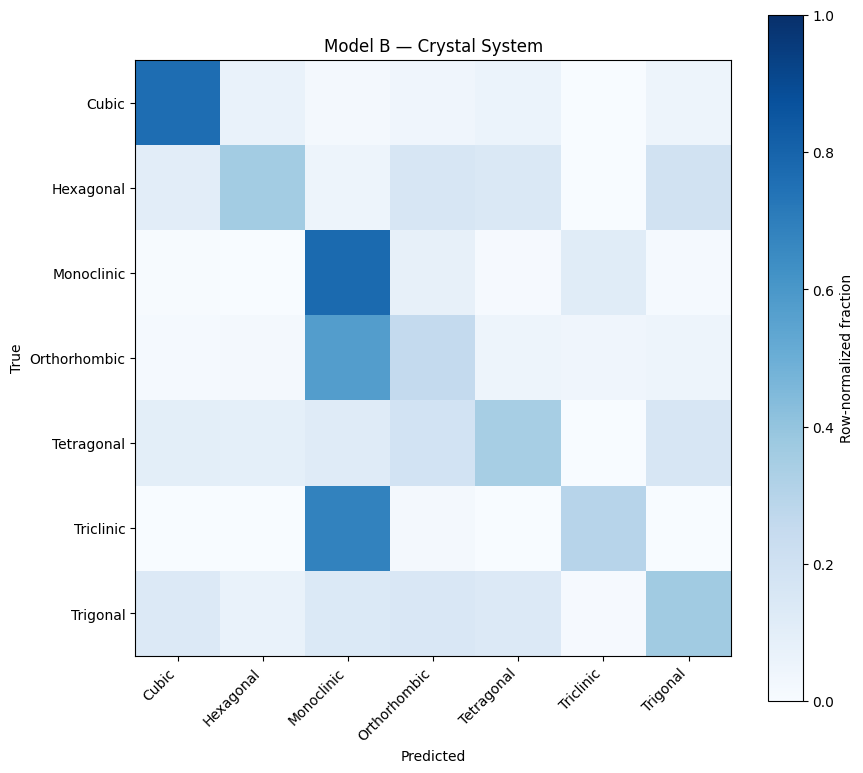

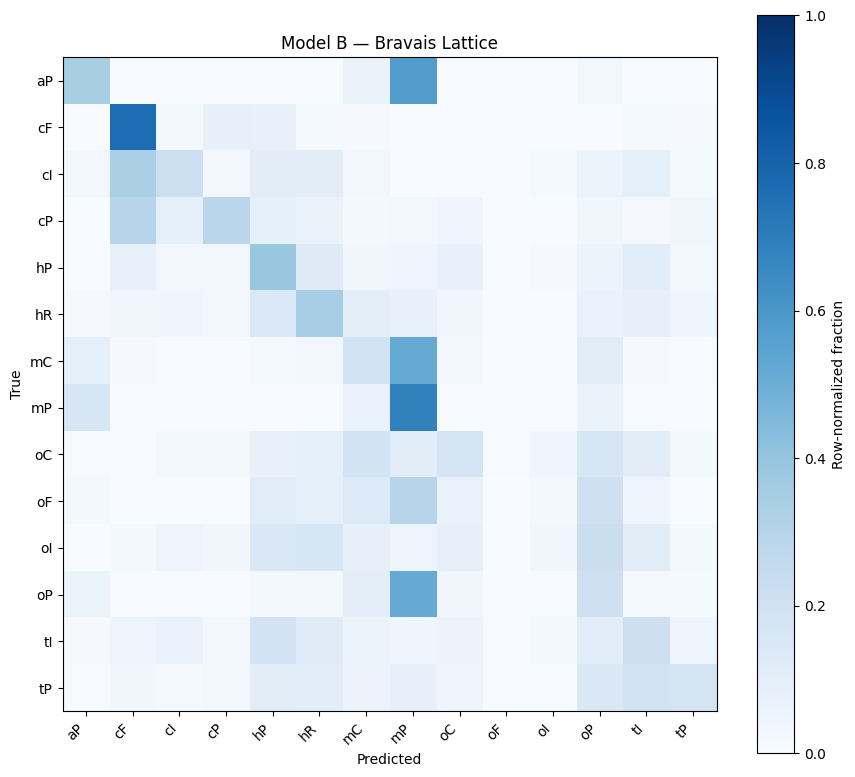

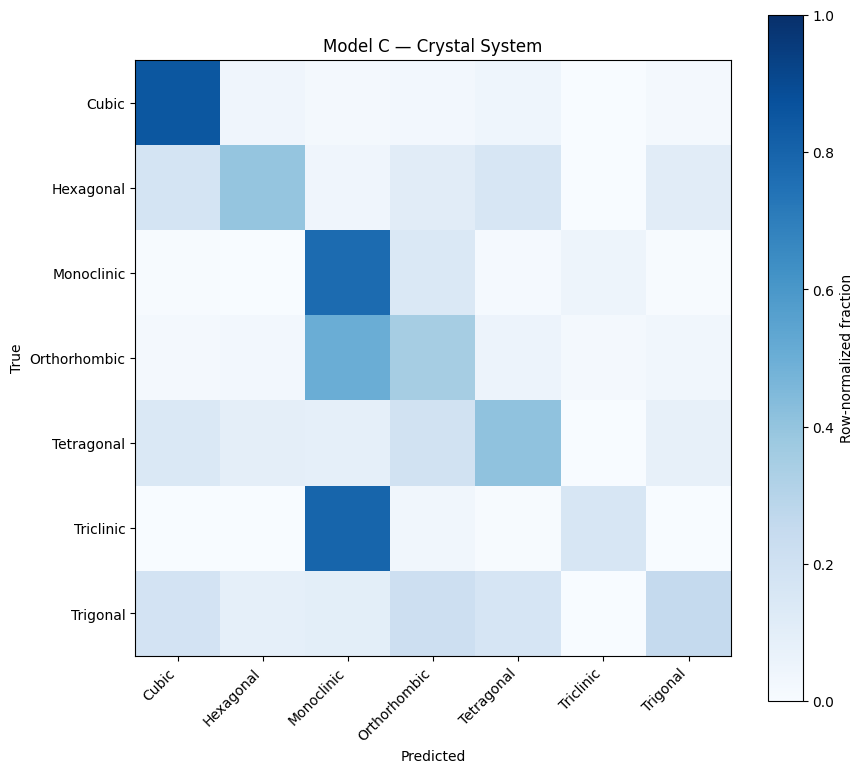

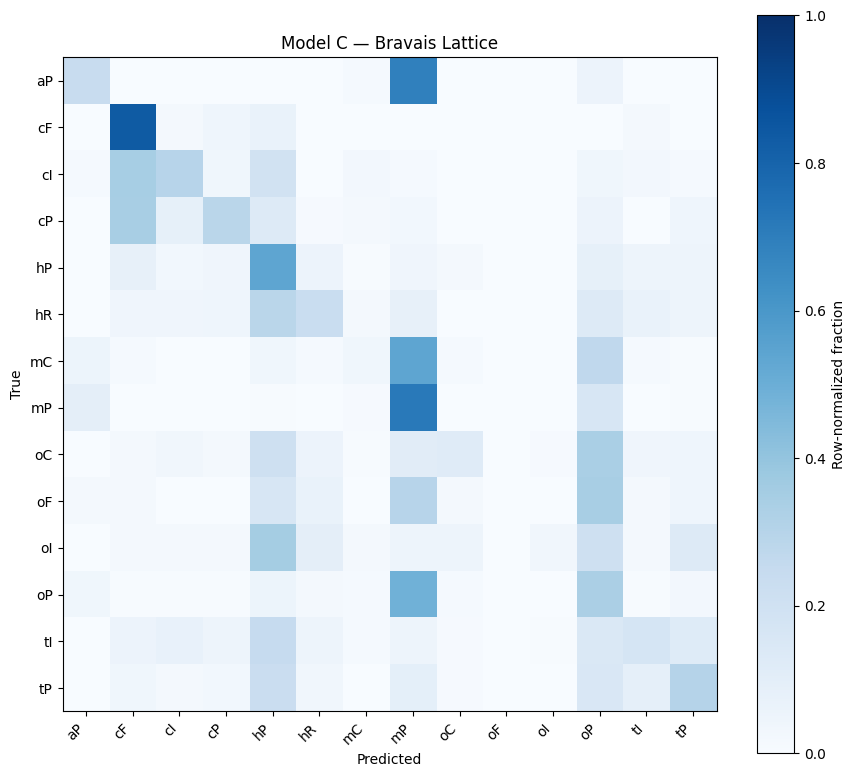

In [35]:
def cm_plot(ytrue,ypred,names,title,path):
    cm=confusion_matrix(ytrue,ypred,labels=np.arange(len(names)))
    rs=cm.sum(axis=1,keepdims=True)
    cmn=np.divide(cm,rs,out=np.zeros_like(cm,dtype=float),where=rs!=0)
    fig,ax=plt.subplots(figsize=(9,8))
    im=ax.imshow(cmn,cmap="Blues",vmin=0,vmax=1)
    ax.set_xticks(range(len(names))); ax.set_yticks(range(len(names)))
    ax.set_xticklabels(names,rotation=45,ha="right"); ax.set_yticklabels(names)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title)
    plt.colorbar(im,ax=ax,label="Row-normalized fraction")
    plt.tight_layout(); plt.savefig(path,dpi=300,bbox_inches="tight"); plt.show()

if B_det is not None:
    cm_plot(Y_CS,B_det["pred_cs"],crystal_classes,"Model B — Crystal System",
            WORK/"model_B_CS_confusion.png")
    cm_plot(Y_BL,B_det["pred_bl"],bravais_classes,"Model B — Bravais Lattice",
            WORK/"model_B_BL_confusion.png")

if C_det is not None:
    cm_plot(Y_CS,C_det["pred_cs"],crystal_classes,"Model C — Crystal System",
            WORK/"model_C_CS_confusion.png")
    cm_plot(Y_BL,C_det["pred_bl"],bravais_classes,"Model C — Bravais Lattice",
            WORK/"model_C_BL_confusion.png")


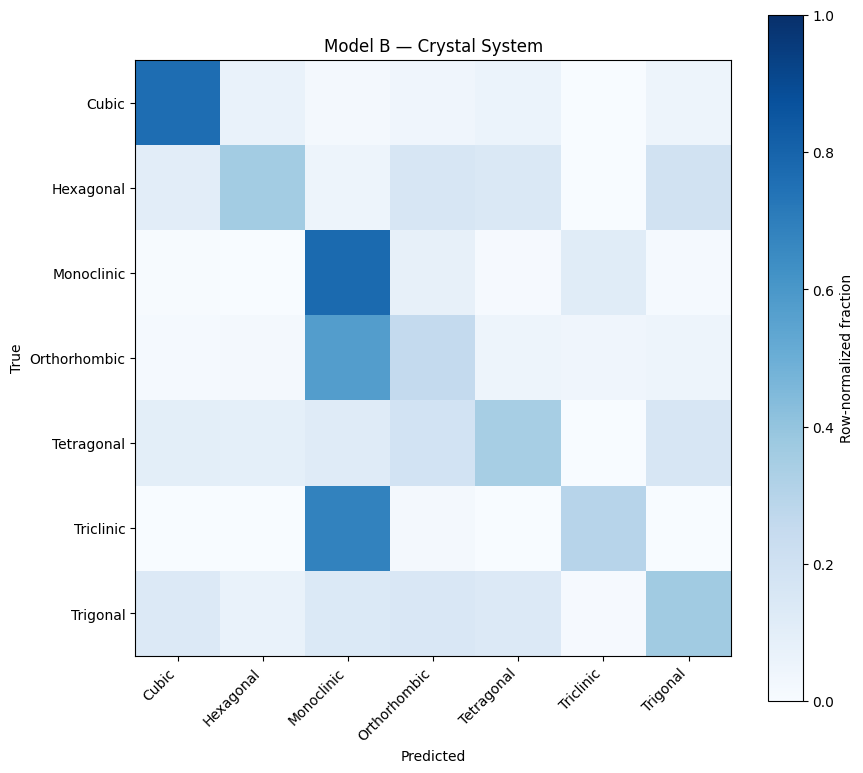

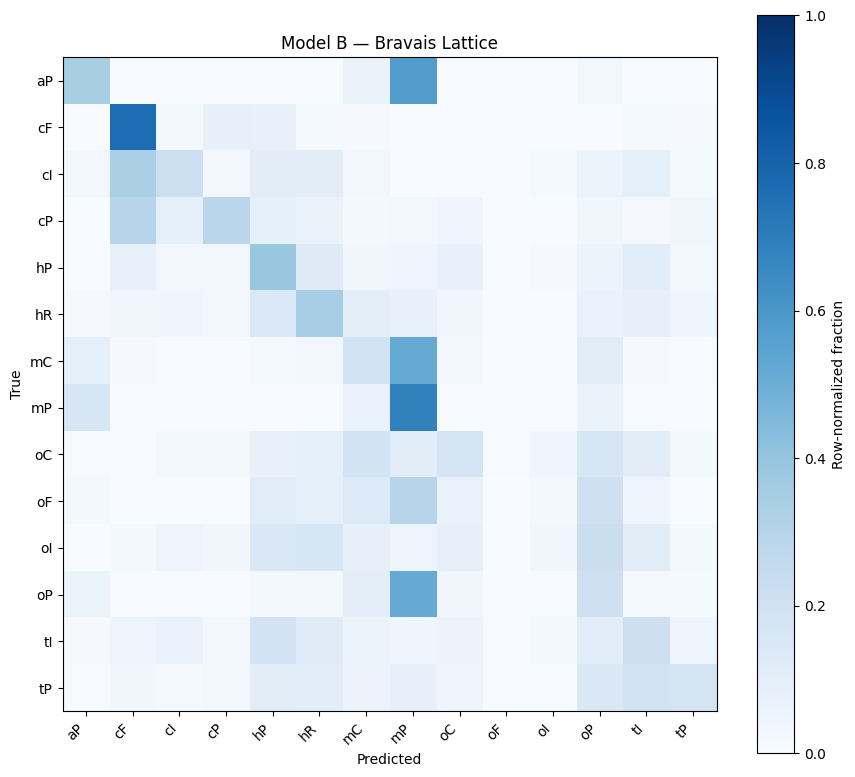

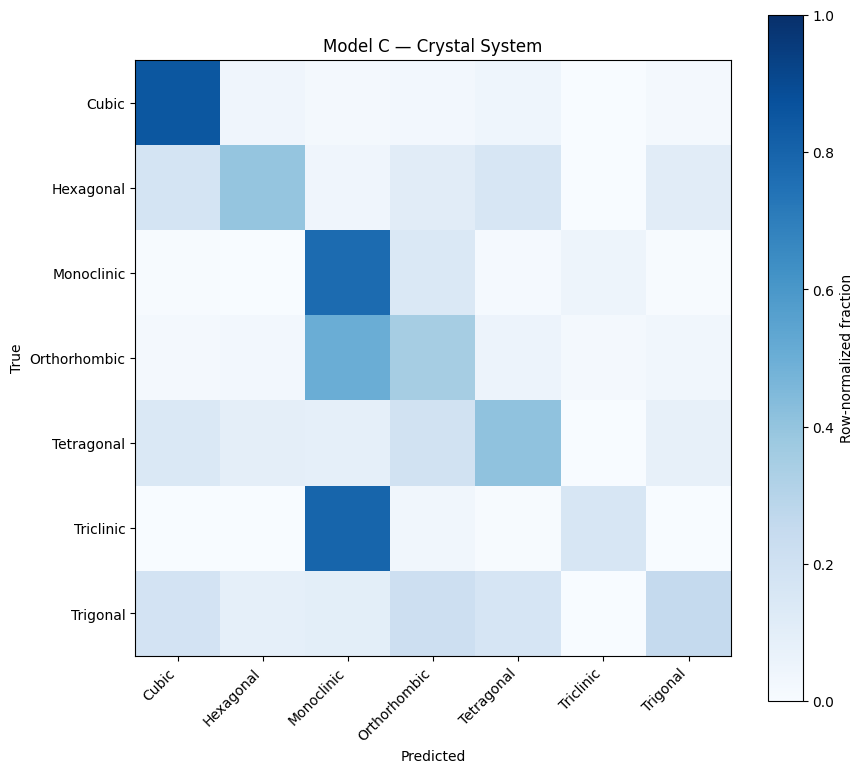

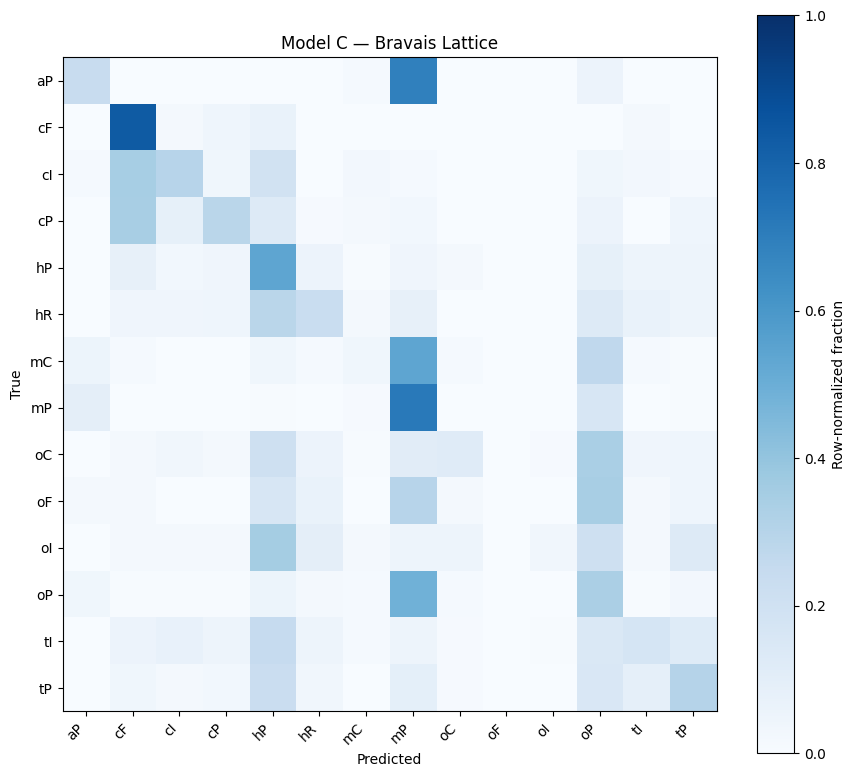

✅ Model C confusion matrices saved.


In [36]:
def cm_plot(ytrue, ypred, names, title, path):

    cm = confusion_matrix(
        ytrue,
        ypred,
        labels=np.arange(len(names))
    )

    rs = cm.sum(axis=1, keepdims=True)

    cmn = np.divide(
        cm,
        rs,
        out=np.zeros_like(cm, dtype=float),
        where=rs != 0
    )

    fig, ax = plt.subplots(figsize=(9, 8))

    im = ax.imshow(
        cmn,
        cmap="Blues",
        vmin=0,
        vmax=1
    )

    ax.set_xticks(range(len(names)))
    ax.set_yticks(range(len(names)))

    ax.set_xticklabels(
        names,
        rotation=45,
        ha="right"
    )

    ax.set_yticklabels(names)

    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)

    plt.colorbar(
        im,
        ax=ax,
        label="Row-normalized fraction"
    )

    plt.tight_layout()

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# MODEL B
# ============================================================

if "B_det" in globals():

    cm_plot(
        Y_CS,
        B_det["pred_cs"],
        crystal_classes,
        "Model B — Crystal System",
        "/kaggle/working/model_B_CS_confusion.png"
    )

    cm_plot(
        Y_BL,
        B_det["pred_bl"],
        bravais_classes,
        "Model B — Bravais Lattice",
        "/kaggle/working/model_B_BL_confusion.png"
    )

else:

    print(
        "⚠️ Model B predictions (B_det) are not available."
    )


# ============================================================
# MODEL C
# ============================================================

if "C_det" in globals():

    cm_plot(
        Y_CS,
        C_det["pred_cs"],
        crystal_classes,
        "Model C — Crystal System",
        "/kaggle/working/model_C_CS_confusion.png"
    )

    cm_plot(
        Y_BL,
        C_det["pred_bl"],
        bravais_classes,
        "Model C — Bravais Lattice",
        "/kaggle/working/model_C_BL_confusion.png"
    )

    print("✅ Model C confusion matrices saved.")

else:

    print("⚠️ C_det is not available.")

In [37]:
import json
import numpy as np

# Save Model A row
with open("/kaggle/working/MODEL_A_RESULT.json", "w") as f:
    json.dump(
        {
            k: None if pd.isna(v)
            else float(v) if isinstance(v, (float, np.floating))
            else v
            for k, v in A_row.items()
        },
        f,
        indent=2
    )

# Save predictions
np.save("/kaggle/working/model_A_pred_sg.npy", A_det["pred_sg"])
np.save("/kaggle/working/model_A_pred_cs.npy", A_det["pred_cs"])
np.save("/kaggle/working/model_A_pred_bl.npy", A_det["pred_bl"])
np.save("/kaggle/working/model_A_sg_probs.npy", A_det["sg_probs"])

# Save weights
model_A.save_weights(
    "/kaggle/working/model_A_FINAL.weights.h5"
)

print("✅ MODEL A EVERYTHING SAVED")

✅ MODEL A EVERYTHING SAVED


In [38]:
# ============================================================
# FINAL TEST EVALUATION — ALL THREE MODELS
# ============================================================

print("Evaluating Model A...")
A_row, A_det = eval_A(model_A)

print("\nEvaluating Model B...")
B_row, B_det = eval_3head(
    model_B,
    "B. 3-head multi-task"
)

print("\nEvaluating Model C...")
C_row, C_det = eval_3head(
    model_C,
    "C. 3-head + consistency"
)

print("\n✅ ALL MODELS EVALUATED")

Evaluating Model A...
123/123 ━━━━━━━━━━━━━━━━━━━━ 7s 60ms/step

Evaluating Model B...
123/123 ━━━━━━━━━━━━━━━━━━━━ 7s 59ms/step

Evaluating Model C...
123/123 ━━━━━━━━━━━━━━━━━━━━ 8s 61ms/step

✅ ALL MODELS EVALUATED


In [39]:
import pandas as pd
import numpy as np

rows = [
    A_row,
    B_row,
    C_row
]

results = pd.DataFrame(rows)

pretty = results.copy()

for c in [
    "SG Top-1",
    "SG Top-5",
    "CS Acc.",
    "BL Acc.",
    "Hierarchy violation"
]:
    pretty[c] = pretty[c].apply(
        lambda x:
        "N/A"
        if pd.isna(x)
        else f"{100*x:.2f}%"
    )

pretty["SG Macro-F1"] = (
    pretty["SG Macro-F1"]
    .map(lambda x: f"{x:.4f}")
)

display(pretty)

,Model,SG Top-1,SG Top-5,SG Macro-F1,CS Acc.,BL Acc.,Hierarchy violation
0,A. Flat SG,31.52%,71.21%,0.0949,50.08%,40.37%,N/A
1,B. 3-head multi-task,31.82%,71.81%,0.1033,51.62%,40.31%,30.11%
2,C. 3-head + consistency,32.48%,71.86%,0.1143,51.81%,41.21%,29.67%


In [40]:
results.to_csv(
    "/kaggle/working/SIMPOD_FINAL_MODEL_COMPARISON.csv",
    index=False
)

pretty.to_csv(
    "/kaggle/working/SIMPOD_FINAL_MODEL_COMPARISON_FORMATTED.csv",
    index=False
)

print("✅ Comparison tables saved")

✅ Comparison tables saved


In [41]:
np.save(
    "/kaggle/working/model_A_pred_sg.npy",
    A_det["pred_sg"]
)

np.save(
    "/kaggle/working/model_A_pred_cs.npy",
    A_det["pred_cs"]
)

np.save(
    "/kaggle/working/model_A_pred_bl.npy",
    A_det["pred_bl"]
)

np.save(
    "/kaggle/working/model_A_sg_probs.npy",
    A_det["sg_probs"]
)

In [42]:
np.save(
    "/kaggle/working/model_B_pred_sg.npy",
    B_det["pred_sg"]
)

np.save(
    "/kaggle/working/model_B_pred_cs.npy",
    B_det["pred_cs"]
)

np.save(
    "/kaggle/working/model_B_pred_bl.npy",
    B_det["pred_bl"]
)

np.save(
    "/kaggle/working/model_B_sg_probs.npy",
    B_det["sg_probs"]
)

np.save(
    "/kaggle/working/model_B_cs_probs.npy",
    B_det["cs_probs"]
)

np.save(
    "/kaggle/working/model_B_bl_probs.npy",
    B_det["bl_probs"]
)

In [43]:
np.save(
    "/kaggle/working/model_C_pred_sg.npy",
    C_det["pred_sg"]
)

np.save(
    "/kaggle/working/model_C_pred_cs.npy",
    C_det["pred_cs"]
)

np.save(
    "/kaggle/working/model_C_pred_bl.npy",
    C_det["pred_bl"]
)

np.save(
    "/kaggle/working/model_C_sg_probs.npy",
    C_det["sg_probs"]
)

np.save(
    "/kaggle/working/model_C_cs_probs.npy",
    C_det["cs_probs"]
)

np.save(
    "/kaggle/working/model_C_bl_probs.npy",
    C_det["bl_probs"]
)

print("✅ ALL predictions safely saved")

✅ ALL predictions safely saved


In [44]:
from sklearn.metrics import classification_report

print("\n================ MODEL A ================\n")

print(
    classification_report(
        Y_CS,
        A_det["pred_cs"],
        target_names=crystal_classes,
        digits=4,
        zero_division=0
    )
)


print("\n================ MODEL B ================\n")

print(
    classification_report(
        Y_CS,
        B_det["pred_cs"],
        target_names=crystal_classes,
        digits=4,
        zero_division=0
    )
)


print("\n================ MODEL C ================\n")

print(
    classification_report(
        Y_CS,
        C_det["pred_cs"],
        target_names=crystal_classes,
        digits=4,
        zero_division=0
    )
)


================ MODEL A ================

              precision    recall  f1-score   support

       Cubic     0.5903    0.7140    0.6462       458
   Hexagonal     0.3493    0.5031    0.4124       318
  Monoclinic     0.5385    0.7766    0.6360      3160
Orthorhombic     0.4411    0.2320    0.3041      1694
  Tetragonal     0.4202    0.3309    0.3702       541
   Triclinic     0.4634    0.2526    0.3270      1330
    Trigonal     0.3555    0.2486    0.2926       366

    accuracy                         0.5008      7867
   macro avg     0.4512    0.4368    0.4269      7867
weighted avg     0.4836    0.5008    0.4696      7867


================ MODEL B ================

              precision    recall  f1-score   support

       Cubic     0.6610    0.7620    0.7079       458
   Hexagonal     0.4302    0.3585    0.3911       318
  Monoclinic     0.5488    0.7747    0.6424      3160
Orthorhombic     0.4662    0.2562    0.3307      1694
  Tetragonal     0.4466    0.3475    0.3909 

In [46]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import numpy as np


def normalized_cm(
    y_true,
    y_pred,
    labels,
    names,
    title,
    save_path
):

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=labels
    )

    row_sum = cm.sum(
        axis=1,
        keepdims=True
    )

    cm_norm = np.divide(
        cm,
        row_sum,
        out=np.zeros_like(
            cm,
            dtype=float
        ),
        where=row_sum != 0
    )

    fig, ax = plt.subplots(
        figsize=(9, 8)
    )

    im = ax.imshow(
        cm_norm,
        cmap="Blues",
        vmin=0,
        vmax=1
    )

    ax.set_xticks(
        np.arange(len(names))
    )

    ax.set_yticks(
        np.arange(len(names))
    )

    ax.set_xticklabels(
        names,
        rotation=45,
        ha="right"
    )

    ax.set_yticklabels(names)

    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

    ax.set_title(title)

    plt.colorbar(
        im,
        ax=ax,
        label="Row-normalized fraction"
    )

    plt.tight_layout()

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

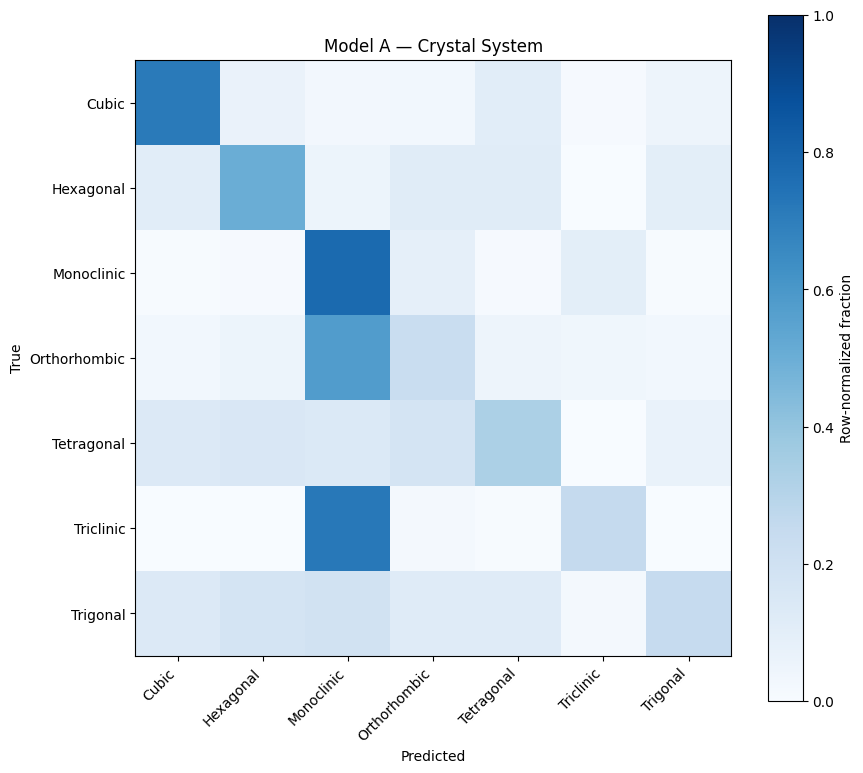

In [47]:
normalized_cm(
    Y_CS,
    A_det["pred_cs"],
    np.arange(len(crystal_classes)),
    crystal_classes,
    "Model A — Crystal System",
    "/kaggle/working/model_A_CS_confusion.png"
)

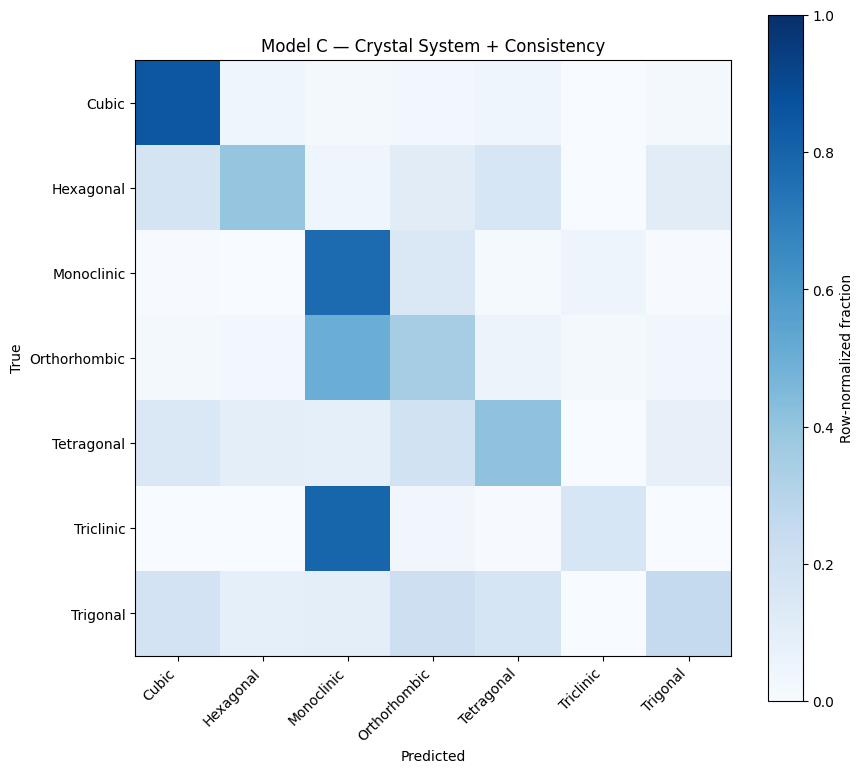

In [48]:
normalized_cm(
    Y_CS,
    C_det["pred_cs"],
    np.arange(len(crystal_classes)),
    crystal_classes,
    "Model C — Crystal System + Consistency",
    "/kaggle/working/model_C_CS_confusion.png"
)

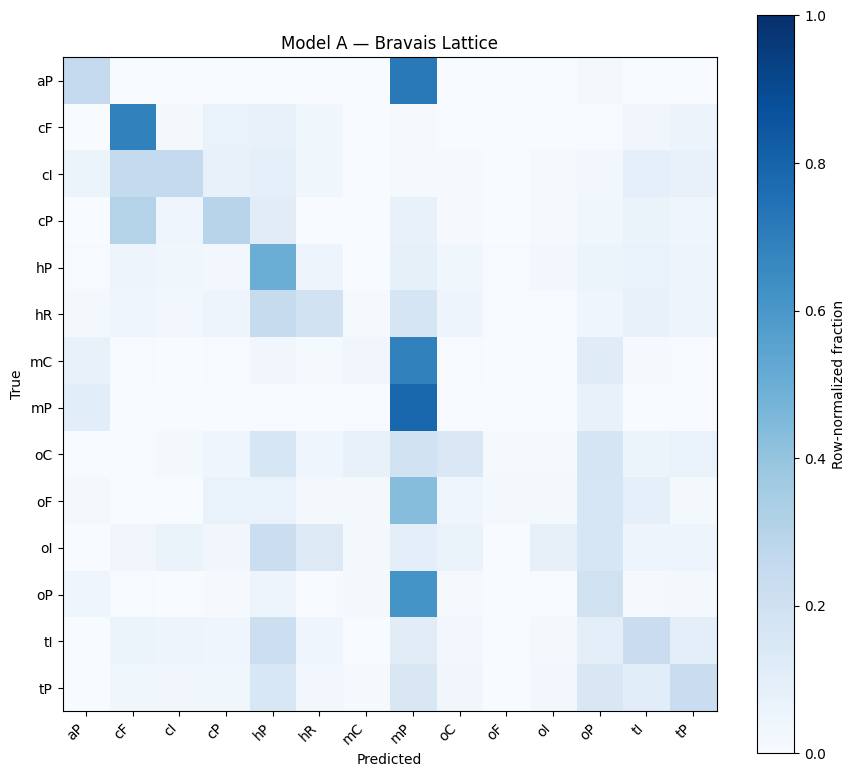

In [49]:
normalized_cm(
    Y_BL,
    A_det["pred_bl"],
    np.arange(len(bravais_classes)),
    bravais_classes,
    "Model A — Bravais Lattice",
    "/kaggle/working/model_A_BL_confusion.png"
)

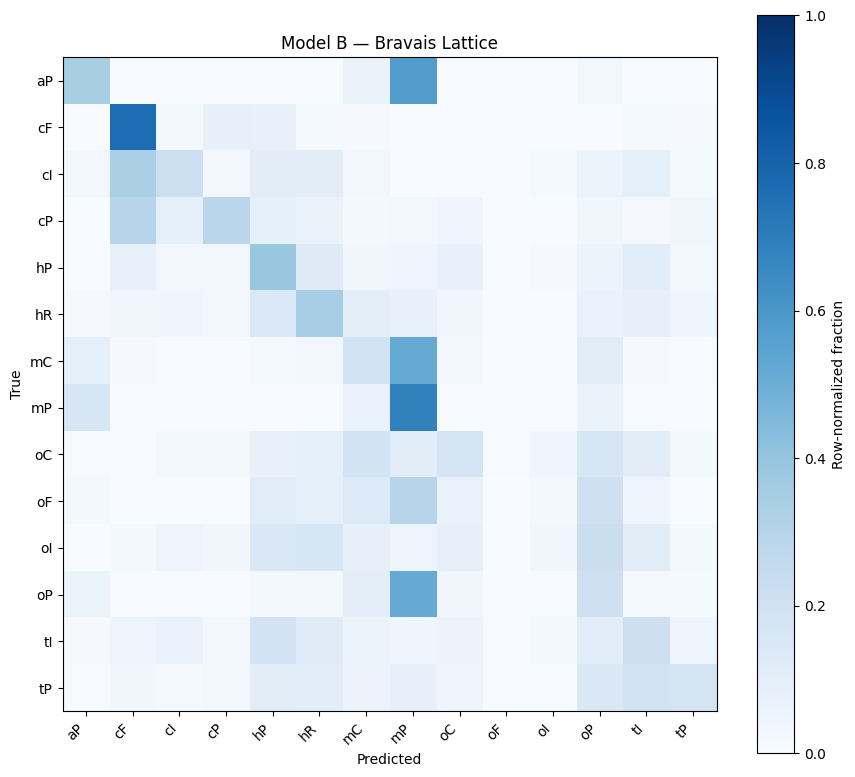

In [50]:
normalized_cm(
    Y_BL,
    B_det["pred_bl"],
    np.arange(len(bravais_classes)),
    bravais_classes,
    "Model B — Bravais Lattice",
    "/kaggle/working/model_B_BL_confusion.png"
)

In [51]:
B_sg_cs = SG_TO_CS[
    B_det["pred_sg"]
]

B_sg_bl = SG_TO_BL[
    B_det["pred_sg"]
]

B_violation = np.mean(

    (B_det["pred_cs"] != B_sg_cs)

    |

    (B_det["pred_bl"] != B_sg_bl)

)

print(
    "Model B Hierarchy Violation:",
    round(B_violation * 100, 2),
    "%"
)

Model B Hierarchy Violation: 30.11 %


In [52]:
C_sg_cs = SG_TO_CS[
    C_det["pred_sg"]
]

C_sg_bl = SG_TO_BL[
    C_det["pred_sg"]
]

C_violation = np.mean(

    (C_det["pred_cs"] != C_sg_cs)

    |

    (C_det["pred_bl"] != C_sg_bl)

)

print(
    "Model C Hierarchy Violation:",
    round(C_violation * 100, 2),
    "%"
)

Model C Hierarchy Violation: 29.67 %


In [56]:
import os
import numpy as np

# ------------------------------------------------------------
# Recover ground-truth labels if required
# ------------------------------------------------------------

if "Y_CS" not in globals():
    Y_CS = test_df["crystal_id"].to_numpy(dtype=int)

if "Y_BL" not in globals():
    Y_BL = test_df["bravais_id"].to_numpy(dtype=int)

if "Y_SG" not in globals():
    Y_SG = test_df["sg_id"].to_numpy(dtype=int)


# ------------------------------------------------------------
# Recover saved predictions if *_det variables are unavailable
# ------------------------------------------------------------

if "A_det" not in globals():
    A_det = {
        "pred_sg": np.load("/kaggle/working/model_A_pred_sg.npy"),
        "pred_cs": np.load("/kaggle/working/model_A_pred_cs.npy"),
        "pred_bl": np.load("/kaggle/working/model_A_pred_bl.npy")
    }

if "B_det" not in globals():
    B_det = {
        "pred_sg": np.load("/kaggle/working/model_B_pred_sg.npy"),
        "pred_cs": np.load("/kaggle/working/model_B_pred_cs.npy"),
        "pred_bl": np.load("/kaggle/working/model_B_pred_bl.npy")
    }

if "C_det" not in globals():
    C_det = {
        "pred_sg": np.load("/kaggle/working/model_C_pred_sg.npy"),
        "pred_cs": np.load("/kaggle/working/model_C_pred_cs.npy"),
        "pred_bl": np.load("/kaggle/working/model_C_pred_bl.npy")
    }

print("✅ Predictions ready")

print("Test samples:", len(Y_CS))
print("A:", len(A_det["pred_cs"]))
print("B:", len(B_det["pred_cs"]))
print("C:", len(C_det["pred_cs"]))

✅ Predictions ready
Test samples: 7867
A: 7867
B: 7867
C: 7867


In [58]:
import os
import numpy as np
import pandas as pd

# ----------------------------------------------------------
# Ground truth labels
# ----------------------------------------------------------
if "Y_CS" not in globals():
    Y_CS = test_df["crystal_id"].to_numpy(dtype=int)

if "Y_BL" not in globals():
    Y_BL = test_df["bravais_id"].to_numpy(dtype=int)

if "Y_SG" not in globals():
    Y_SG = test_df["sg_id"].to_numpy(dtype=int)

# ----------------------------------------------------------
# Recover predictions if not already in memory
# ----------------------------------------------------------
if "A_det" not in globals():
    A_det = {
        "pred_sg": np.load("/kaggle/working/model_A_pred_sg.npy"),
        "pred_cs": np.load("/kaggle/working/model_A_pred_cs.npy"),
        "pred_bl": np.load("/kaggle/working/model_A_pred_bl.npy"),
    }

if "B_det" not in globals():
    B_det = {
        "pred_sg": np.load("/kaggle/working/model_B_pred_sg.npy"),
        "pred_cs": np.load("/kaggle/working/model_B_pred_cs.npy"),
        "pred_bl": np.load("/kaggle/working/model_B_pred_bl.npy"),
    }

if "C_det" not in globals():
    C_det = {
        "pred_sg": np.load("/kaggle/working/model_C_pred_sg.npy"),
        "pred_cs": np.load("/kaggle/working/model_C_pred_cs.npy"),
        "pred_bl": np.load("/kaggle/working/model_C_pred_bl.npy"),
    }

print("✅ Predictions ready")
print("A:", len(A_det["pred_cs"]))
print("B:", len(B_det["pred_cs"]))
print("C:", len(C_det["pred_cs"]))

✅ Predictions ready
A: 7867
B: 7867
C: 7867


In [59]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix_pretty(
    y_true,
    y_pred,
    class_names,
    title,
    save_path,
    normalize=True,
    figsize=(10, 8),
    annot_fontsize=9,
    tick_fontsize=10,
    title_fontsize=14,
    cmap="Blues",
    show_zero=False,
    show_percent=True,
    show_counts=True
):
    """
    Creates a clean confusion matrix with numbers inside each cell.
    Each cell can display:
        count
        (percentage)
    """

    labels = np.arange(len(class_names))

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=labels
    )

    if normalize:
        row_sum = cm.sum(axis=1, keepdims=True)
        cm_norm = np.divide(
            cm,
            row_sum,
            out=np.zeros_like(cm, dtype=float),
            where=row_sum != 0
        ) * 100.0
    else:
        cm_norm = cm.astype(float)

    fig, ax = plt.subplots(figsize=figsize, facecolor="white")
    im = ax.imshow(cm_norm, cmap=cmap, vmin=0, vmax=(100 if normalize else cm.max()))

    # ticks
    ax.set_xticks(np.arange(len(class_names)))
    ax.set_yticks(np.arange(len(class_names)))

    ax.set_xticklabels(class_names, rotation=45, ha="right", fontsize=tick_fontsize)
    ax.set_yticklabels(class_names, fontsize=tick_fontsize)

    ax.set_xlabel("Predicted Label", fontsize=12)
    ax.set_ylabel("True Label", fontsize=12)
    ax.set_title(title, fontsize=title_fontsize, pad=14)

    # grid lines for cleaner visual
    ax.set_xticks(np.arange(-.5, len(class_names), 1), minor=True)
    ax.set_yticks(np.arange(-.5, len(class_names), 1), minor=True)
    ax.grid(which="minor", color="gray", linestyle='-', linewidth=0.5, alpha=0.35)
    ax.tick_params(which="minor", bottom=False, left=False)

    # annotation
    max_val = cm_norm.max() if cm_norm.size > 0 else 0
    threshold = max_val * 0.55

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):

            count = cm[i, j]
            pct = cm_norm[i, j]

            if (count == 0) and (not show_zero):
                continue

            txt_parts = []
            if show_counts:
                txt_parts.append(f"{count}")
            if show_percent:
                txt_parts.append(f"({pct:.1f}%)")

            txt = "\n".join(txt_parts)

            color = "white" if pct > threshold else "black"

            ax.text(
                j, i, txt,
                ha="center",
                va="center",
                color=color,
                fontsize=annot_fontsize,
                fontweight="bold" if i == j else "normal"
            )

    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Percentage of True Class (%)" if normalize else "Count", fontsize=11)

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("✅ Saved:", save_path)

    return cm

Prediction availability:
A: dict_keys(['sg_probs', 'pred_sg', 'pred_cs', 'pred_bl'])
B: dict_keys(['cs_probs', 'bl_probs', 'sg_probs', 'pred_cs', 'pred_bl', 'pred_sg'])
C: dict_keys(['cs_probs', 'bl_probs', 'sg_probs', 'pred_cs', 'pred_bl', 'pred_sg'])


# Final Model Comparison

,Model,SG Top-1,SG Top-5,SG Macro-F1,CS Acc.,BL Acc.,Hierarchy violation
0,A. Flat SG,31.52%,71.21%,0.0949,50.08%,40.37%,N/A
1,B. 3-head multi-task,31.82%,71.81%,0.1033,51.62%,40.31%,30.11%
2,C. 3-head + consistency,32.48%,71.86%,0.1143,51.81%,41.21%,29.67%


## MODEL A — FLAT SG: Crystal System Report

,precision,recall,f1-score,support
Cubic,0.5903,0.7140,0.6462,458.0000
Hexagonal,0.3493,0.5031,0.4124,318.0000
Monoclinic,0.5385,0.7766,0.6360,3160.0000
Orthorhombic,0.4411,0.2320,0.3041,1694.0000
Tetragonal,0.4202,0.3309,0.3702,541.0000
Triclinic,0.4634,0.2526,0.3270,1330.0000
Trigonal,0.3555,0.2486,0.2926,366.0000
accuracy,0.5008,0.5008,0.5008,0.5008
macro avg,0.4512,0.4368,0.4269,7867.0000
weighted avg,0.4836,0.5008,0.4696,7867.0000


## MODEL B — MULTI-TASK: Crystal System Report

,precision,recall,f1-score,support
Cubic,0.6610,0.7620,0.7079,458.0000
Hexagonal,0.4302,0.3585,0.3911,318.0000
Monoclinic,0.5488,0.7747,0.6424,3160.0000
Orthorhombic,0.4662,0.2562,0.3307,1694.0000
Tetragonal,0.4466,0.3475,0.3909,541.0000
Triclinic,0.4736,0.2962,0.3645,1330.0000
Trigonal,0.3124,0.3661,0.3371,366.0000
accuracy,0.5162,0.5162,0.5162,0.5162
macro avg,0.4769,0.4516,0.4521,7867.0000
weighted avg,0.5020,0.5162,0.4905,7867.0000


## MODEL C — CONSISTENCY: Crystal System Report

,precision,recall,f1-score,support
Cubic,0.6040,0.8493,0.7060,458.0000
Hexagonal,0.4582,0.3962,0.4250,318.0000
Monoclinic,0.5481,0.7722,0.6411,3160.0000
Orthorhombic,0.4456,0.3506,0.3925,1694.0000
Tetragonal,0.4400,0.4067,0.4227,541.0000
Triclinic,0.5322,0.1617,0.2480,1330.0000
Trigonal,0.3552,0.2514,0.2944,366.0000
accuracy,0.5181,0.5181,0.5181,0.5181
macro avg,0.4833,0.4554,0.4471,7867.0000
weighted avg,0.5065,0.5181,0.4850,7867.0000


# Crystal System Confusion Matrices

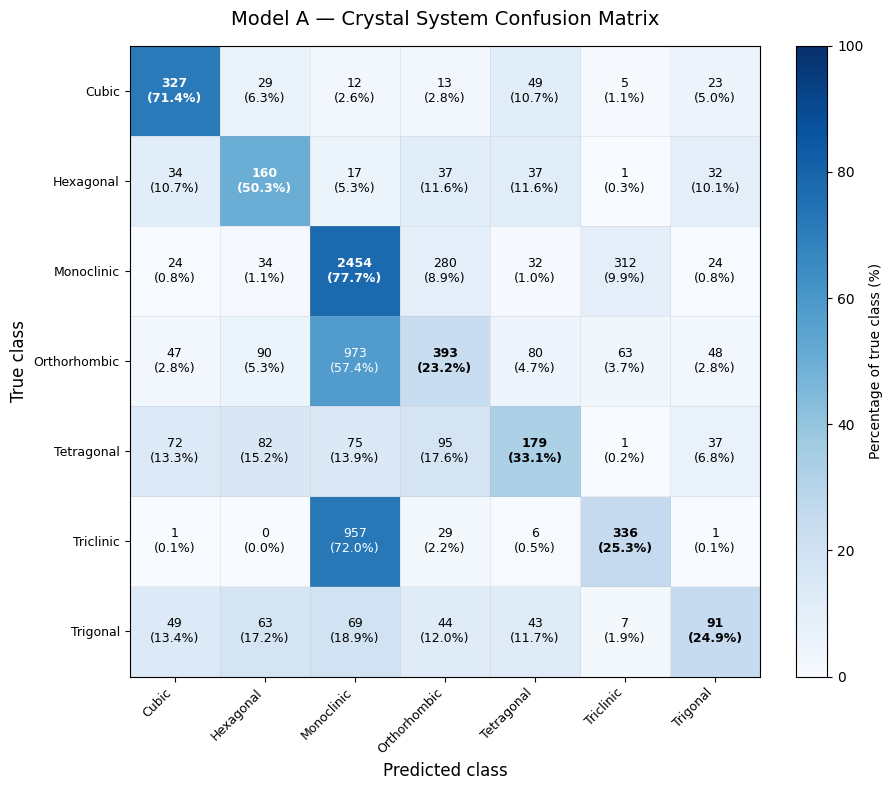

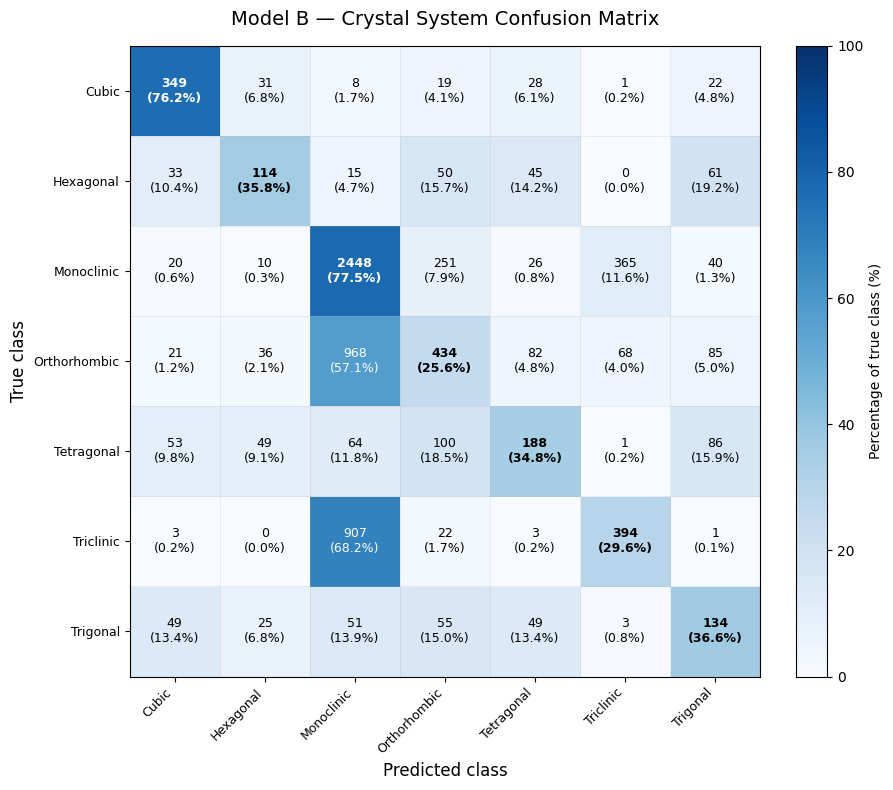

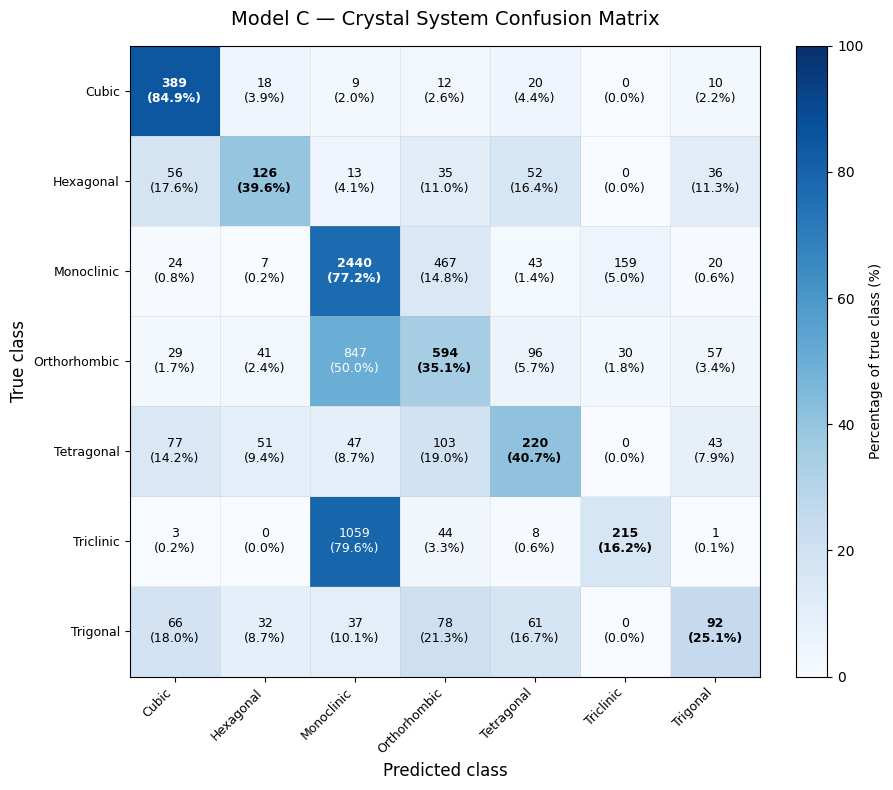

## MODEL A — FLAT SG: Bravais Lattice Report

,precision,recall,f1-score,support
aP,0.4634,0.2526,0.3270,1330.0000
cF,0.5812,0.6838,0.6284,272.0000
cI,0.2174,0.2564,0.2353,78.0000
cP,0.2254,0.2963,0.2560,108.0000
hP,0.3700,0.5036,0.4266,421.0000
hR,0.3546,0.1901,0.2475,263.0000
mC,0.2451,0.0322,0.0569,777.0000
mP,0.4220,0.7889,0.5499,2383.0000
oC,0.2407,0.1469,0.1825,177.0000
oF,0.0833,0.0227,0.0357,44.0000


## MODEL B — MULTI-TASK: Bravais Lattice Report

,precision,recall,f1-score,support
aP,0.4565,0.3429,0.3916,1330.0000
cF,0.5960,0.7647,0.6699,272.0000
cI,0.1848,0.2179,0.2000,78.0000
cP,0.2870,0.2870,0.2870,108.0000
hP,0.4165,0.3848,0.4000,421.0000
hR,0.2835,0.3460,0.3116,263.0000
mC,0.2217,0.1866,0.2027,777.0000
mP,0.4503,0.6861,0.5437,2383.0000
oC,0.1667,0.1751,0.1708,177.0000
oF,0.0000,0.0000,0.0000,44.0000


## MODEL C — CONSISTENCY: Bravais Lattice Report

,precision,recall,f1-score,support
aP,0.4922,0.2361,0.3191,1330.0000
cF,0.5821,0.8346,0.6858,272.0000
cI,0.2277,0.2949,0.2570,78.0000
cP,0.2768,0.2870,0.2818,108.0000
hP,0.3429,0.5368,0.4185,421.0000
hR,0.3506,0.2319,0.2792,263.0000
mC,0.2727,0.0386,0.0676,777.0000
mP,0.4448,0.7172,0.5491,2383.0000
oC,0.2727,0.1186,0.1654,177.0000
oF,0.0000,0.0000,0.0000,44.0000


# Bravais Lattice Confusion Matrices

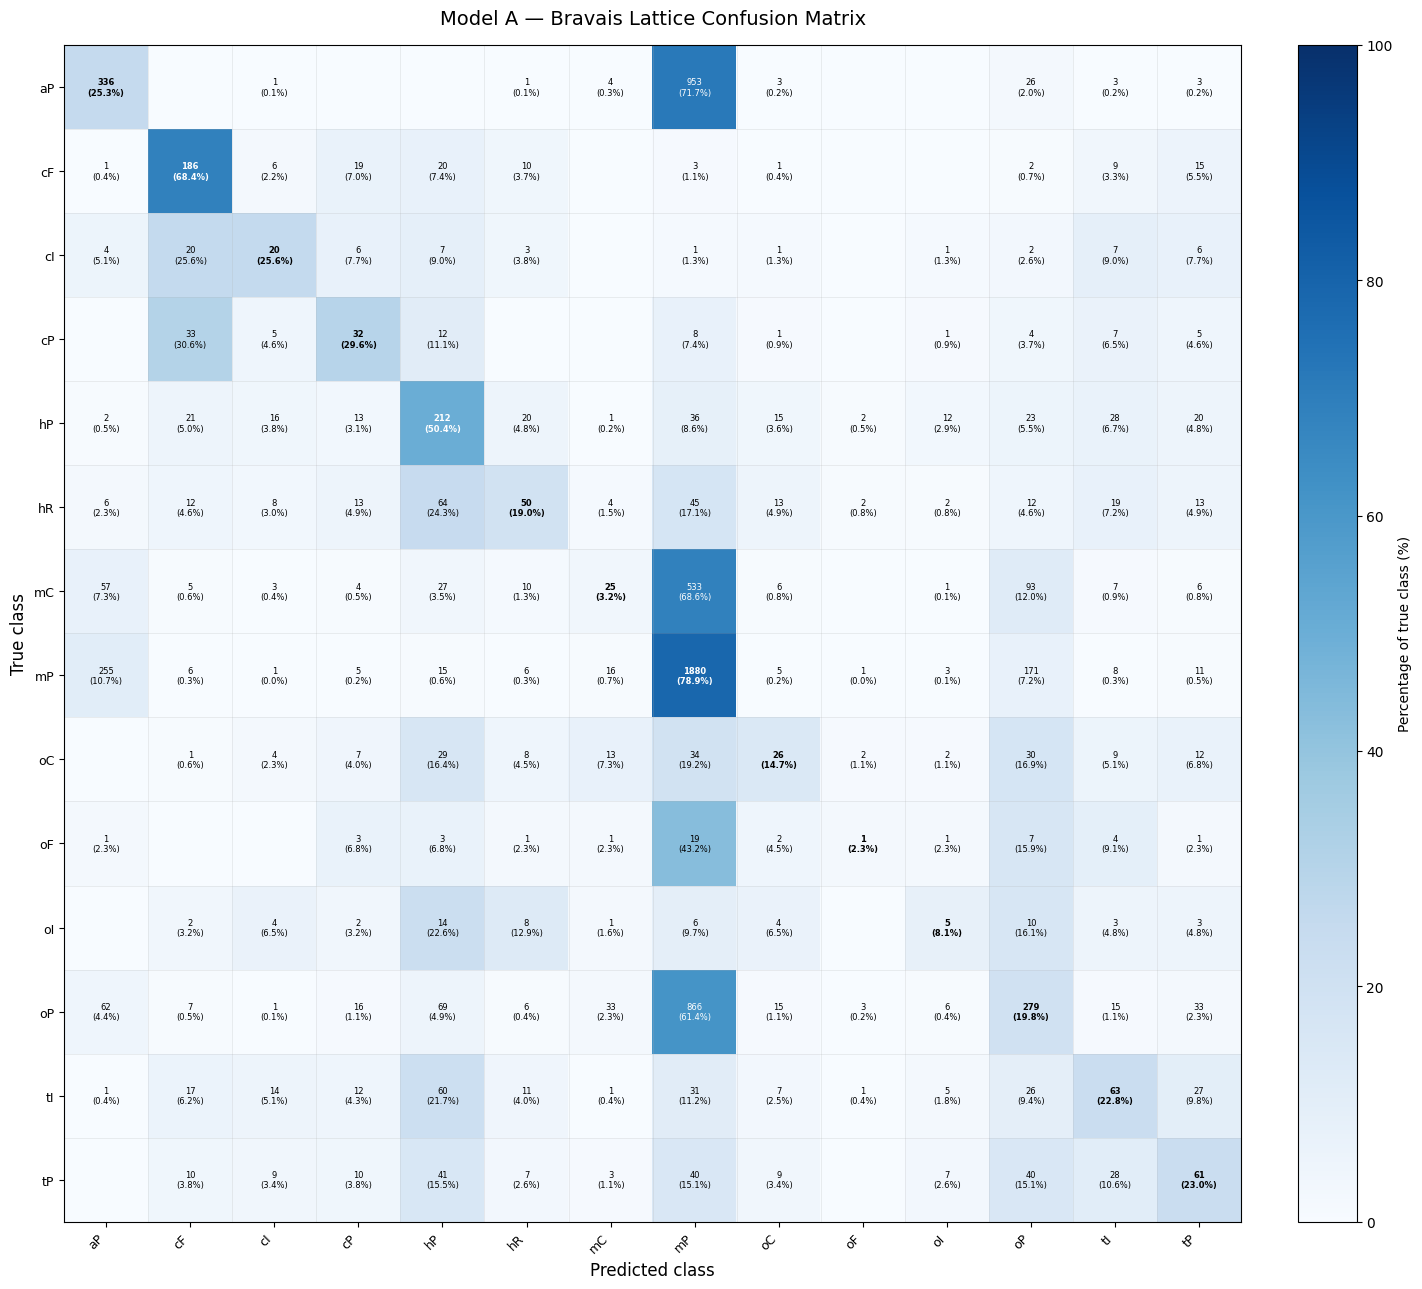

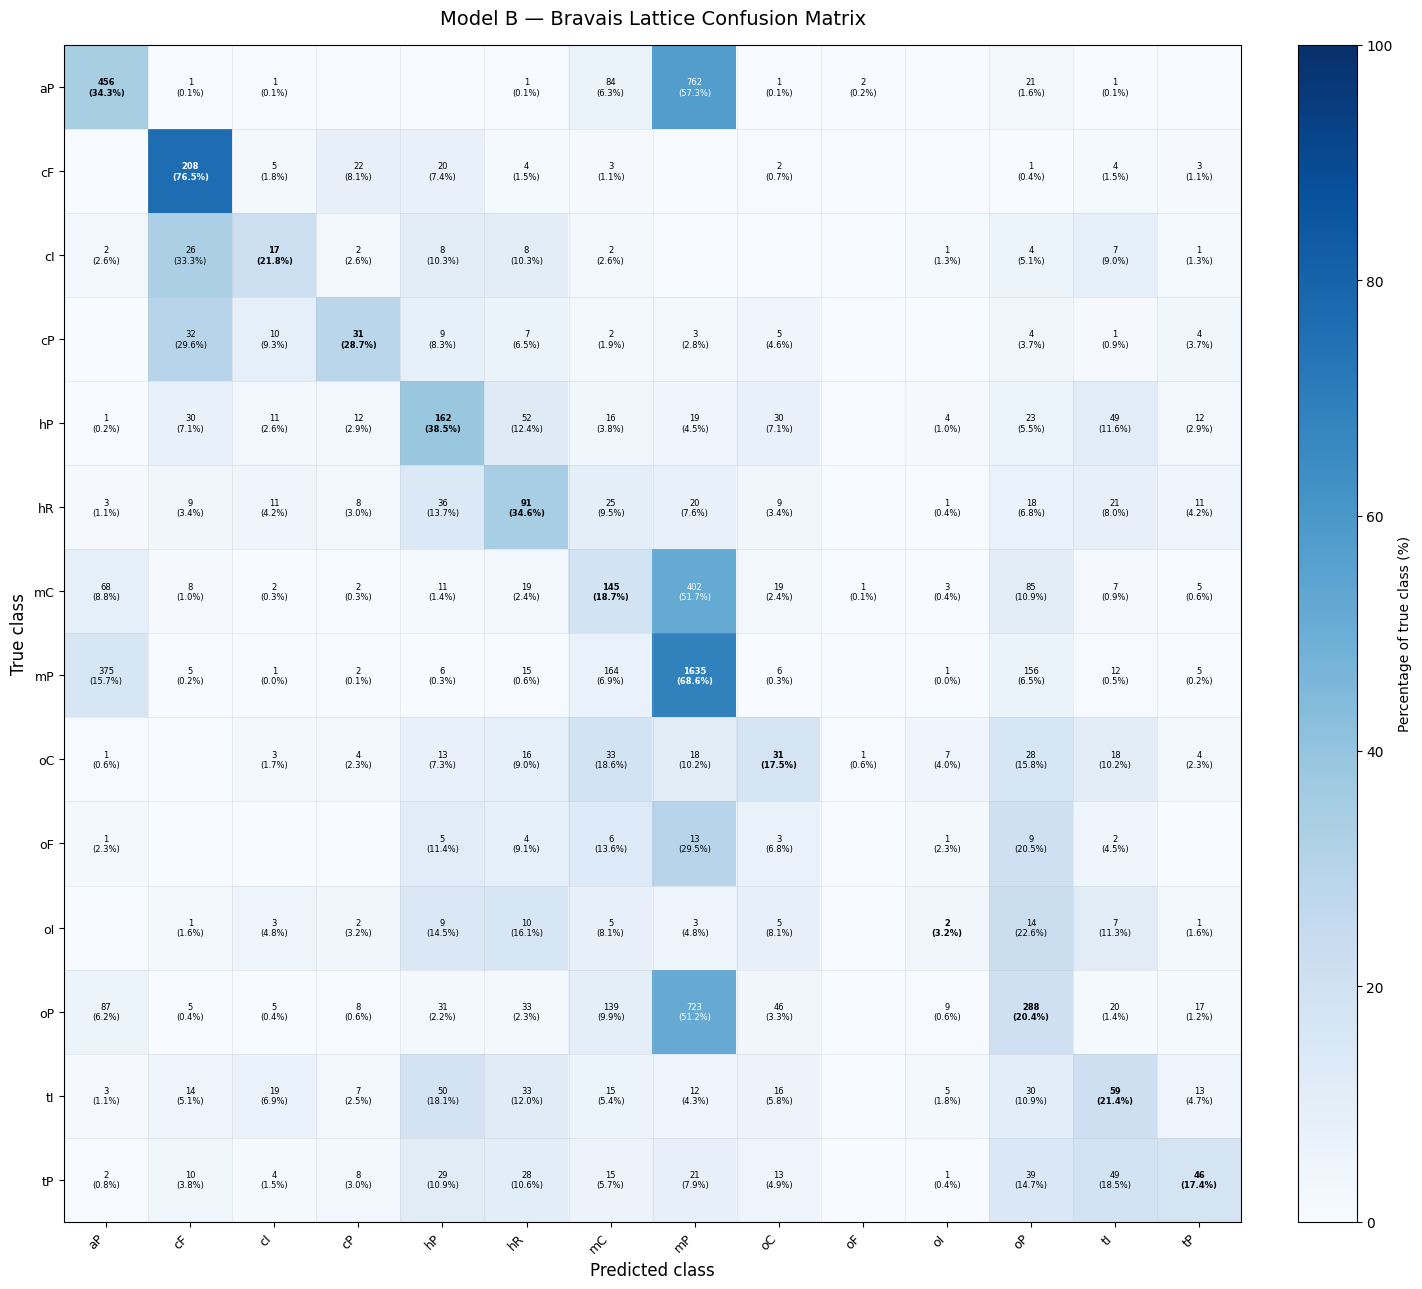

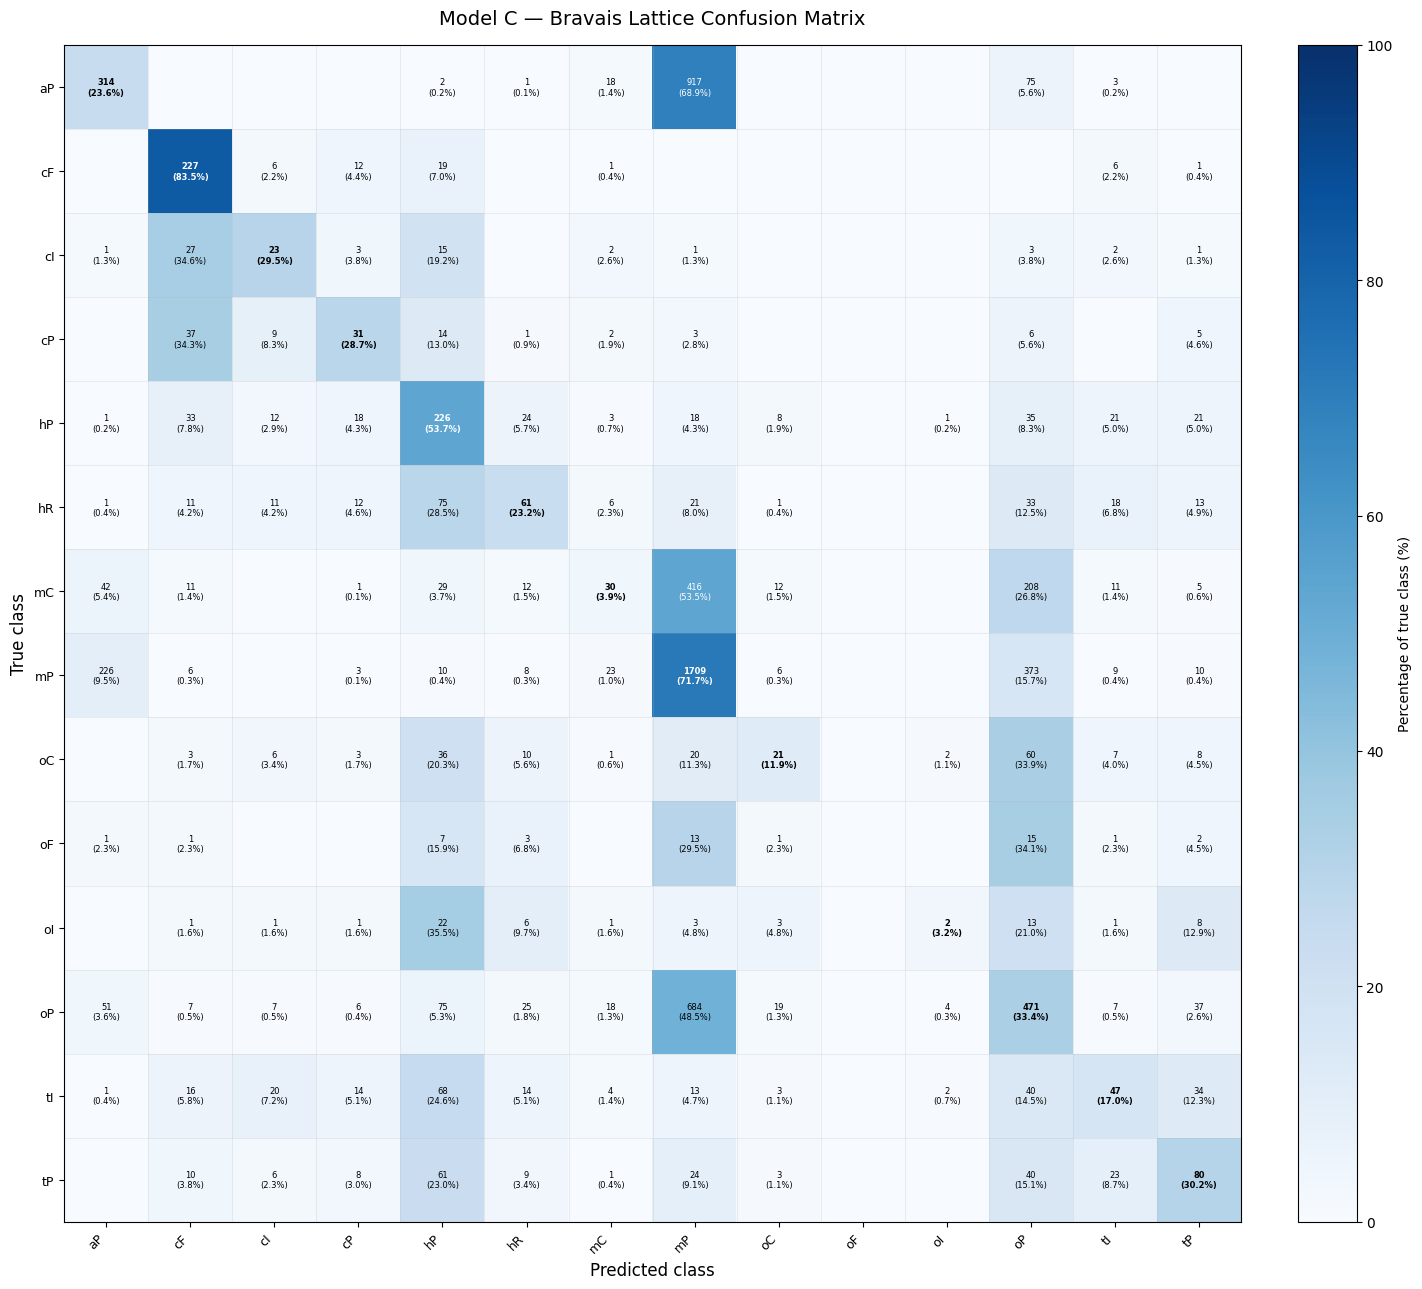

# Space Group — Top 20 Classes

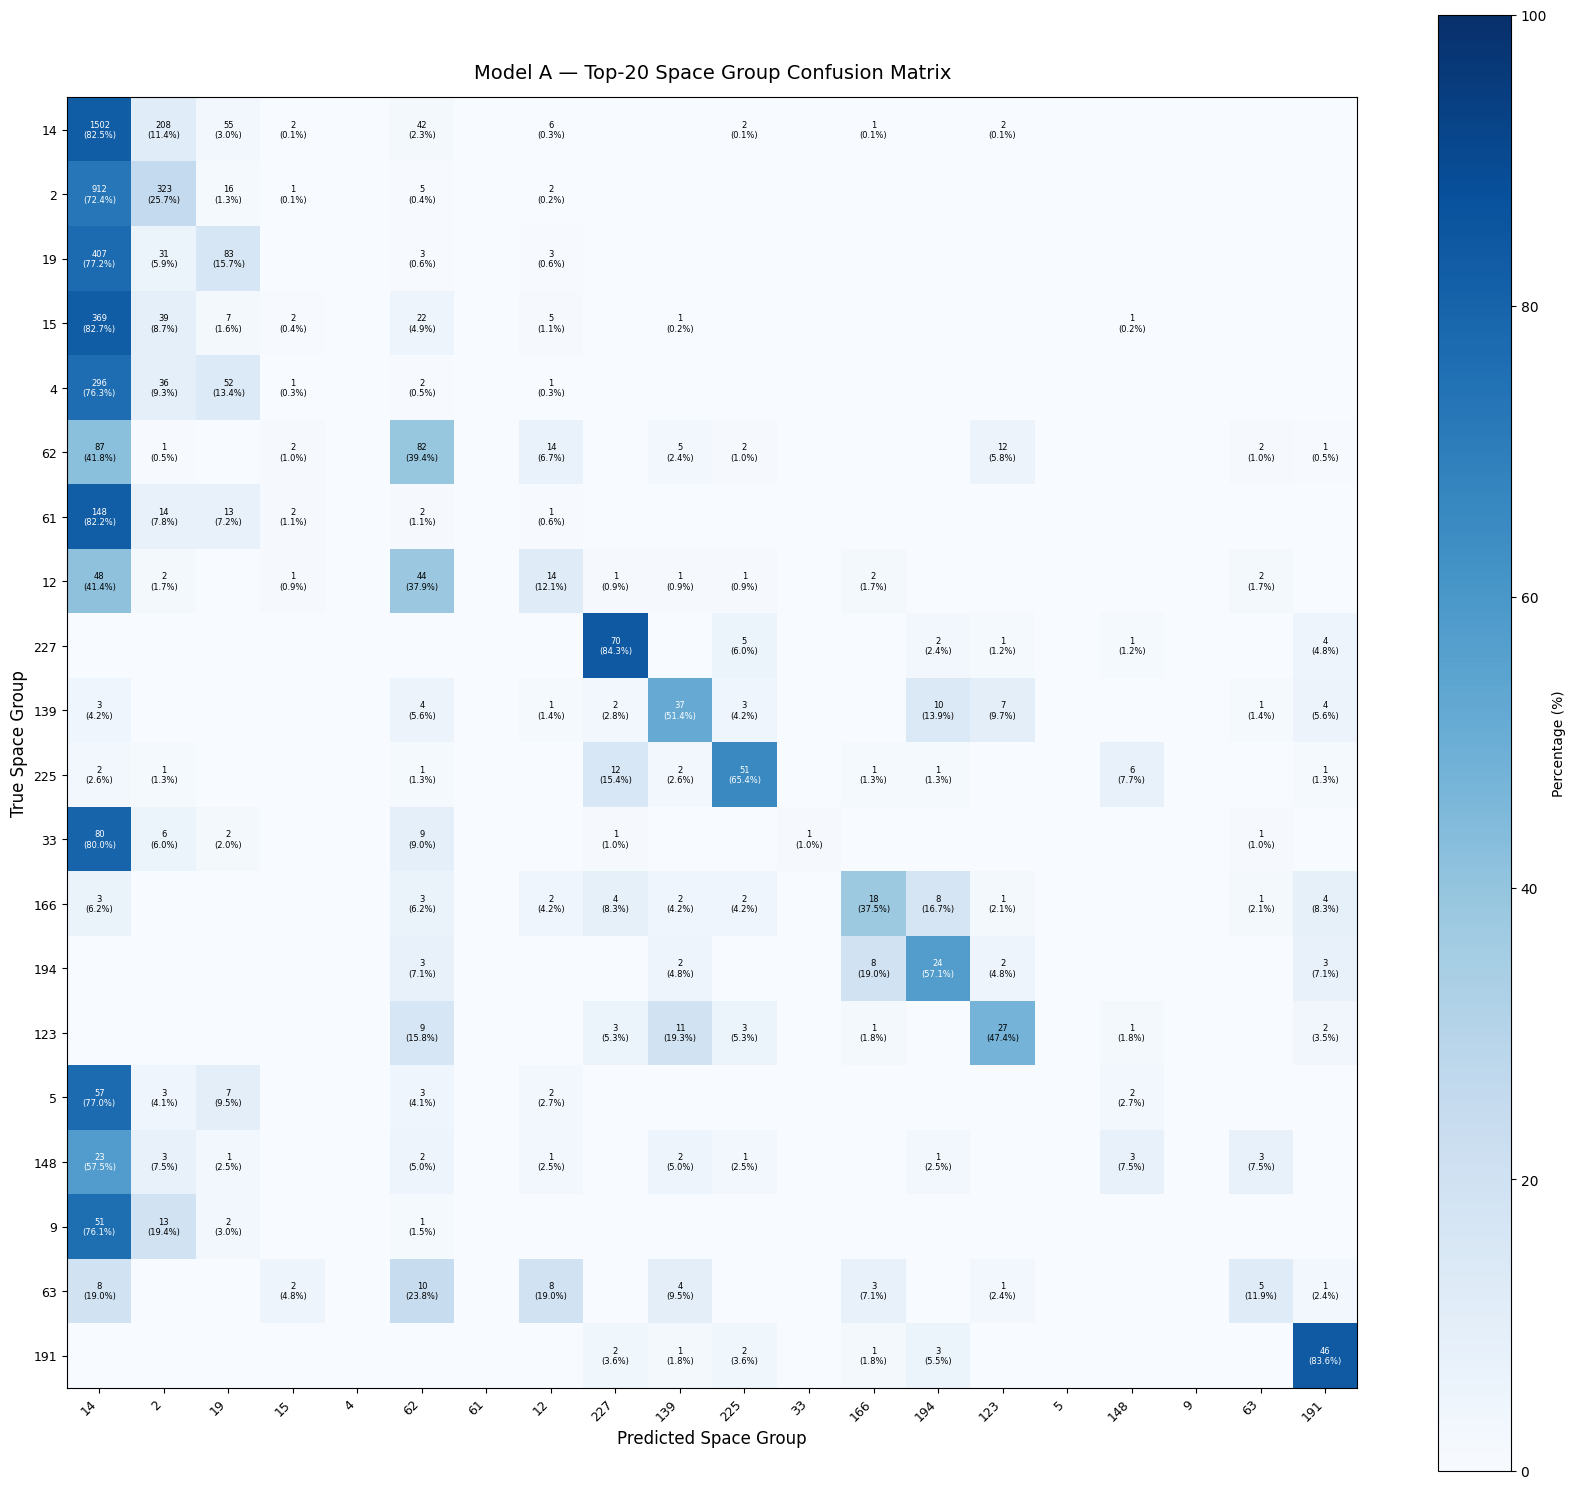

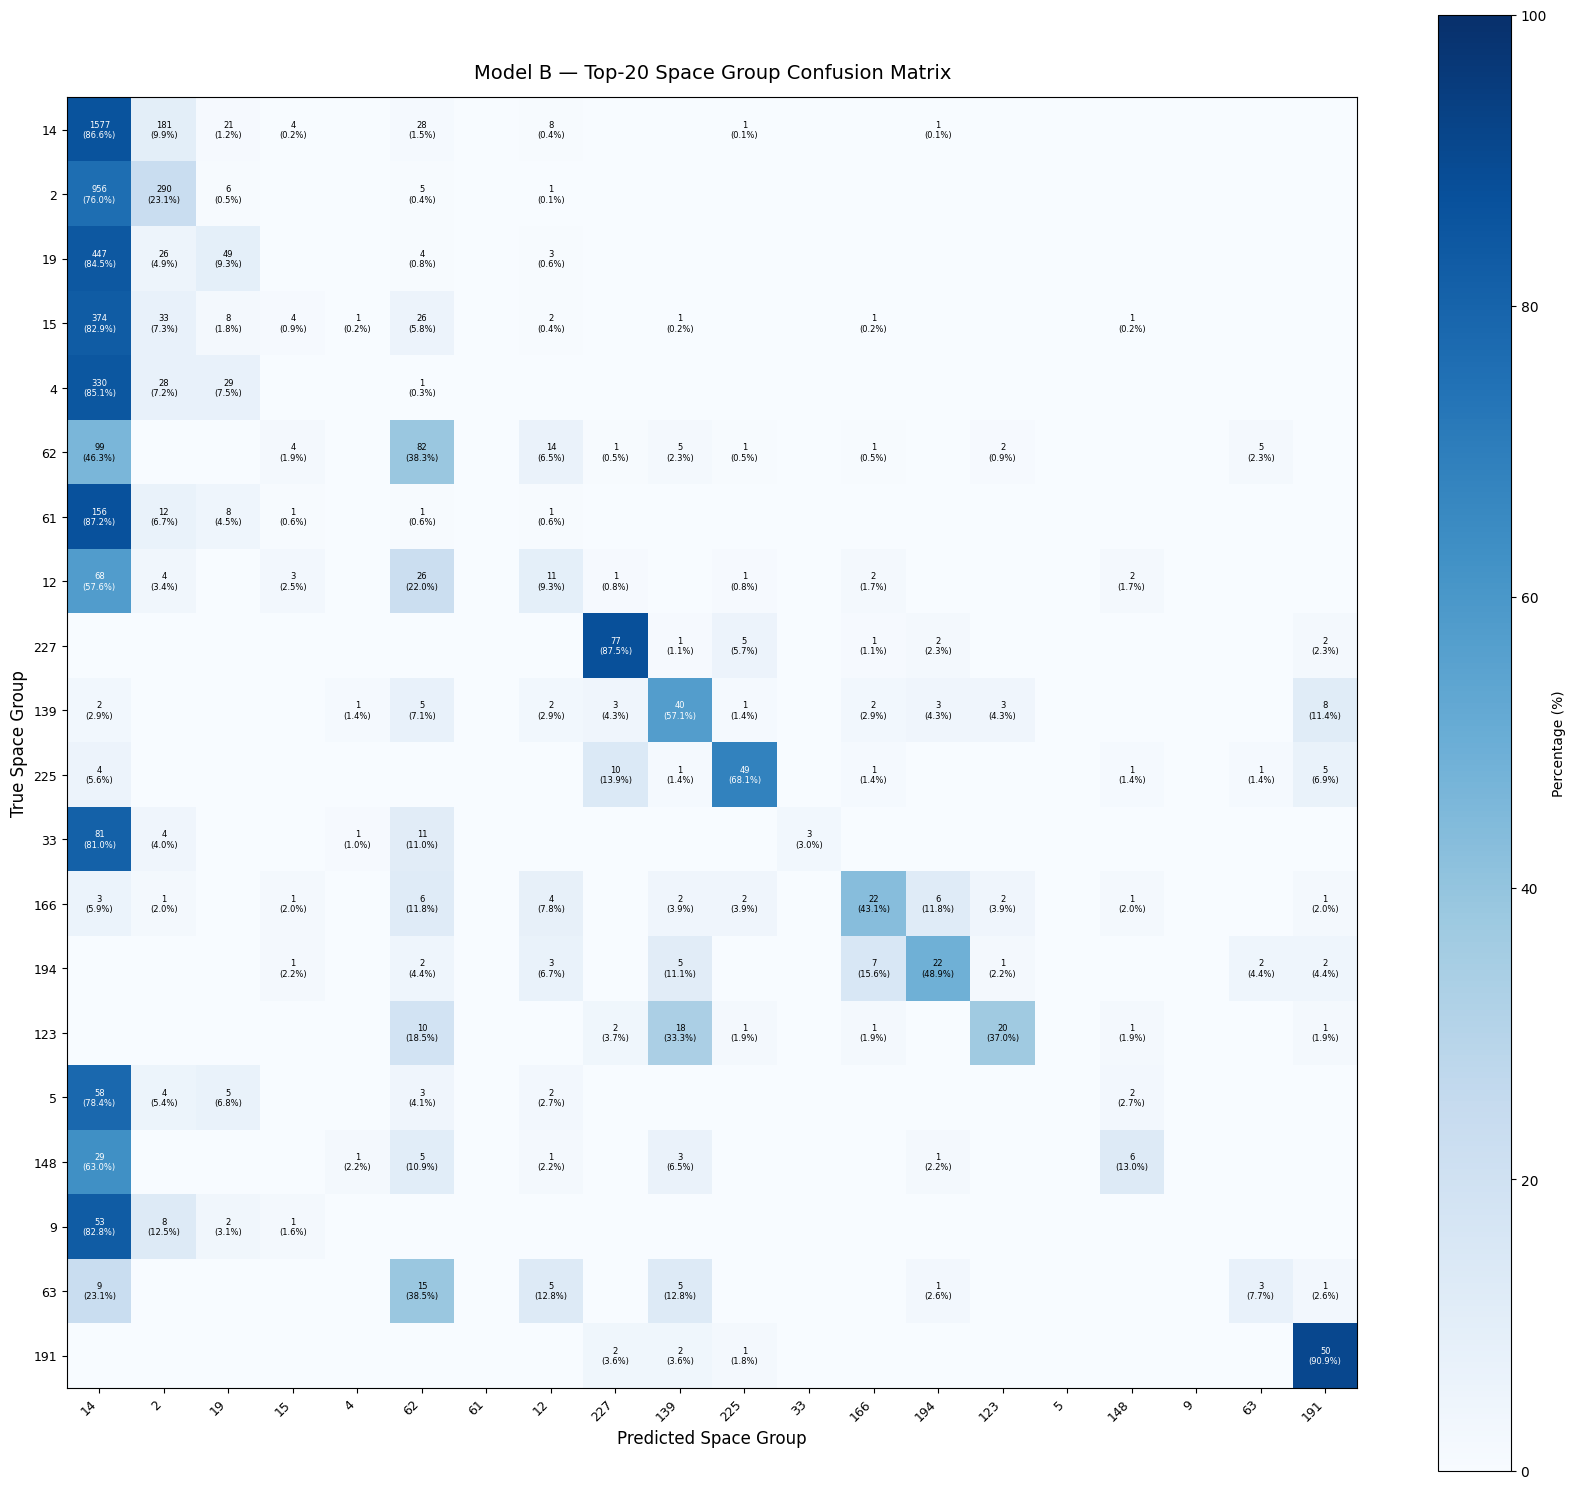

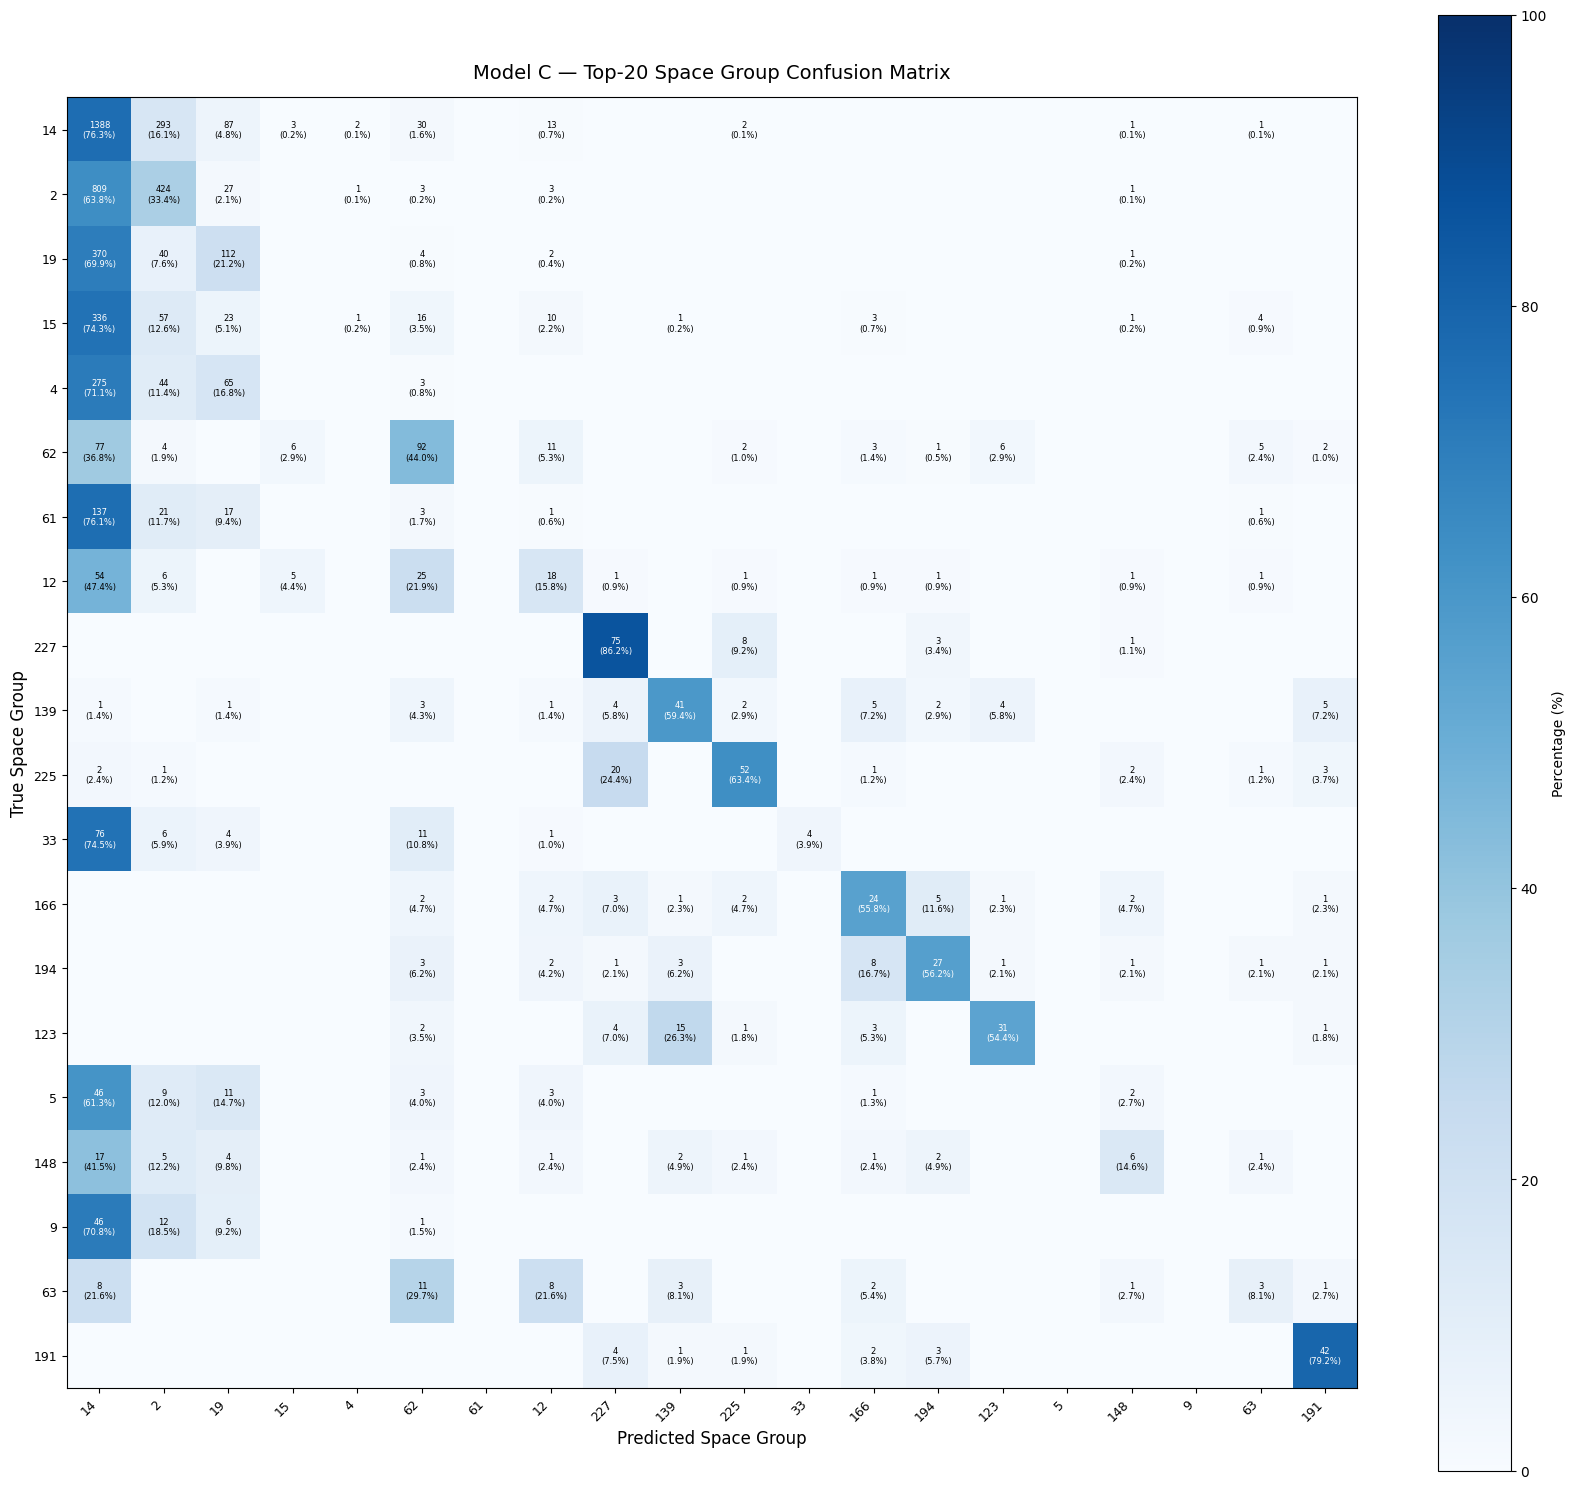

# Full Space Group Confusion Matrices — Counts

## Model A — Full SG Confusion Matrix

,Pred 1,Pred 2,Pred 4,Pred 5,Pred 7,Pred 8,Pred 9,Pred 10,Pred 11,Pred 12,...,Pred 217,Pred 218,Pred 220,Pred 221,Pred 223,Pred 225,Pred 226,Pred 227,Pred 229,Pred 230
True 1,0,13,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
True 2,0,323,0,0,0,0,0,0,0,2,...,0,0,0,0,0,0,0,0,1,0
True 4,0,36,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
True 5,0,3,0,0,0,0,0,0,0,2,...,0,0,0,0,0,0,0,0,0,0
True 7,0,3,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
True 225,0,1,0,0,0,0,0,0,0,0,...,0,1,1,4,0,51,0,12,0,0
True 226,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
True 227,0,0,0,0,0,0,0,0,0,0,...,0,0,0,4,0,5,0,70,0,1
True 229,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,4,0,3,0,0


## Model B — Full SG Confusion Matrix

,Pred 1,Pred 2,Pred 4,Pred 5,Pred 7,Pred 8,Pred 9,Pred 10,Pred 11,Pred 12,...,Pred 217,Pred 218,Pred 220,Pred 221,Pred 223,Pred 225,Pred 226,Pred 227,Pred 229,Pred 230
True 1,0,11,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
True 2,0,290,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
True 4,0,28,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
True 5,0,4,0,0,0,0,0,0,0,2,...,0,0,0,0,0,0,0,0,0,0
True 7,0,2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
True 225,0,0,0,0,0,0,0,0,0,0,...,0,0,0,5,0,49,0,10,1,0
True 226,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
True 227,0,0,0,0,0,0,0,0,0,0,...,1,0,0,4,0,5,1,77,0,0
True 229,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,6,0,3,1,0


## Model C — Full SG Confusion Matrix

,Pred 1,Pred 2,Pred 4,Pred 5,Pred 7,Pred 8,Pred 9,Pred 10,Pred 11,Pred 12,...,Pred 217,Pred 218,Pred 220,Pred 221,Pred 223,Pred 225,Pred 226,Pred 227,Pred 229,Pred 230
True 1,0,18,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
True 2,0,424,1,0,0,0,0,0,0,3,...,0,0,0,0,0,0,0,0,0,0
True 4,0,44,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
True 5,0,9,0,0,0,0,0,0,0,3,...,0,0,0,0,0,0,0,0,0,0
True 7,0,6,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
True 225,0,1,0,0,0,0,0,0,0,0,...,0,0,0,4,0,52,0,20,0,2
True 226,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
True 227,0,0,0,0,0,0,0,0,0,0,...,2,0,0,3,1,8,1,75,0,1
True 229,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,5,0,5,0,0


# Hierarchy Consistency

,Model,Hierarchy Violation (%)
0,Model B — Multi-task,30.11
1,Model C — Consistency,29.67


# ✅ COMPLETE SIMPOD RESULTS DISPLAYED

In [60]:
# ================================================================
# SIMPOD — COMPLETE FINAL RESULTS FOR PAPER
# Models A, B and C
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# ================================================================
# 0. PREPARE / RECOVER GROUND TRUTH
# ================================================================

if "Y_CS" not in globals():
    Y_CS = test_df["crystal_id"].to_numpy(dtype=int)

if "Y_BL" not in globals():
    Y_BL = test_df["bravais_id"].to_numpy(dtype=int)

if "Y_SG" not in globals():
    Y_SG = test_df["sg_id"].to_numpy(dtype=int)


# ================================================================
# 1. RECOVER PREDICTIONS IF REQUIRED
# ================================================================

def load_det(prefix):

    base = "/kaggle/working"

    det = {}

    for key, suffix in [
        ("pred_sg", "pred_sg.npy"),
        ("pred_cs", "pred_cs.npy"),
        ("pred_bl", "pred_bl.npy"),
    ]:

        path = f"{base}/model_{prefix}_{suffix}"

        if os.path.exists(path):
            det[key] = np.load(path)

    return det


if "A_det" not in globals():
    A_det = load_det("A")

if "B_det" not in globals():
    B_det = load_det("B")

if "C_det" not in globals():
    C_det = load_det("C")


print("Prediction availability:")
print("A:", A_det.keys())
print("B:", B_det.keys())
print("C:", C_det.keys())


# ================================================================
# 2. FINAL MODEL COMPARISON TABLE
# ================================================================

display(Markdown("# Final Model Comparison"))

rows = []

for variable in ["A_row", "B_row", "C_row"]:

    if variable in globals():
        rows.append(globals()[variable])


if len(rows) > 0:

    results = pd.DataFrame(rows)

    pretty = results.copy()

    percentage_columns = [
        "SG Top-1",
        "SG Top-5",
        "CS Acc.",
        "BL Acc.",
        "Hierarchy violation"
    ]

    for c in percentage_columns:

        if c in pretty.columns:

            pretty[c] = pretty[c].apply(
                lambda x:
                "N/A"
                if pd.isna(x)
                else f"{100*x:.2f}%"
            )

    if "SG Macro-F1" in pretty.columns:

        pretty["SG Macro-F1"] = (
            pretty["SG Macro-F1"]
            .apply(lambda x: f"{x:.4f}")
        )

    display(pretty)

else:

    print("⚠️ A_row/B_row/C_row unavailable.")


# ================================================================
# 3. CONFUSION MATRIX FUNCTION
#    Displays:
#
#        COUNT
#       (XX.X%)
#
# ================================================================

def plot_cm_numbers(
    y_true,
    y_pred,
    class_names,
    title,
    figsize=(10, 8),
    fontsize=8,
    show_zero=True
):

    labels = np.arange(len(class_names))

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=labels
    )

    row_totals = cm.sum(
        axis=1,
        keepdims=True
    )

    cm_pct = np.divide(
        cm,
        row_totals,
        out=np.zeros_like(
            cm,
            dtype=float
        ),
        where=row_totals != 0
    ) * 100


    fig, ax = plt.subplots(
        figsize=figsize
    )

    image = ax.imshow(
        cm_pct,
        cmap="Blues",
        vmin=0,
        vmax=100
    )


    # Labels
    ax.set_xticks(
        np.arange(len(class_names))
    )

    ax.set_yticks(
        np.arange(len(class_names))
    )

    ax.set_xticklabels(
        class_names,
        rotation=45,
        ha="right",
        fontsize=9
    )

    ax.set_yticklabels(
        class_names,
        fontsize=9
    )


    ax.set_xlabel(
        "Predicted class",
        fontsize=12
    )

    ax.set_ylabel(
        "True class",
        fontsize=12
    )

    ax.set_title(
        title,
        fontsize=14,
        pad=15
    )


    # Cell borders
    ax.set_xticks(
        np.arange(-0.5, len(class_names), 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, len(class_names), 1),
        minor=True
    )

    ax.grid(
        which="minor",
        linewidth=0.5,
        alpha=0.3
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )


    # Numbers inside cells
    for i in range(cm.shape[0]):

        for j in range(cm.shape[1]):

            count = cm[i, j]
            pct = cm_pct[i, j]

            if count == 0 and not show_zero:
                continue

            text = (
                f"{count}\n"
                f"({pct:.1f}%)"
            )

            text_color = (
                "white"
                if pct >= 50
                else "black"
            )

            ax.text(
                j,
                i,
                text,
                ha="center",
                va="center",
                fontsize=fontsize,
                color=text_color,
                fontweight=(
                    "bold"
                    if i == j
                    else "normal"
                )
            )


    cbar = plt.colorbar(
        image,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )

    cbar.set_label(
        "Percentage of true class (%)"
    )

    plt.tight_layout()
    plt.show()

    return cm


# ================================================================
# 4. CRYSTAL SYSTEM CLASSIFICATION REPORTS
# ================================================================

for model_name, det in [
    ("MODEL A — FLAT SG", A_det),
    ("MODEL B — MULTI-TASK", B_det),
    ("MODEL C — CONSISTENCY", C_det)
]:

    display(
        Markdown(
            f"## {model_name}: Crystal System Report"
        )
    )

    report = classification_report(
        Y_CS,
        det["pred_cs"],
        target_names=crystal_classes,
        output_dict=True,
        digits=4,
        zero_division=0
    )

    report_df = pd.DataFrame(
        report
    ).transpose()

    display(
        report_df.round(4)
    )


# ================================================================
# 5. CRYSTAL SYSTEM CONFUSION MATRICES
# ================================================================

display(
    Markdown(
        "# Crystal System Confusion Matrices"
    )
)


cm_A_CS = plot_cm_numbers(
    Y_CS,
    A_det["pred_cs"],
    crystal_classes,
    "Model A — Crystal System Confusion Matrix",
    figsize=(10, 8),
    fontsize=9,
    show_zero=True
)


cm_B_CS = plot_cm_numbers(
    Y_CS,
    B_det["pred_cs"],
    crystal_classes,
    "Model B — Crystal System Confusion Matrix",
    figsize=(10, 8),
    fontsize=9,
    show_zero=True
)


cm_C_CS = plot_cm_numbers(
    Y_CS,
    C_det["pred_cs"],
    crystal_classes,
    "Model C — Crystal System Confusion Matrix",
    figsize=(10, 8),
    fontsize=9,
    show_zero=True
)


# ================================================================
# 6. BRAVAIS CLASSIFICATION REPORTS
# ================================================================

for model_name, det in [
    ("MODEL A — FLAT SG", A_det),
    ("MODEL B — MULTI-TASK", B_det),
    ("MODEL C — CONSISTENCY", C_det)
]:

    display(
        Markdown(
            f"## {model_name}: Bravais Lattice Report"
        )
    )

    report = classification_report(
        Y_BL,
        det["pred_bl"],
        target_names=bravais_classes,
        output_dict=True,
        digits=4,
        zero_division=0
    )

    report_df = pd.DataFrame(
        report
    ).transpose()

    display(
        report_df.round(4)
    )


# ================================================================
# 7. BRAVAIS CONFUSION MATRICES
# ================================================================

display(
    Markdown(
        "# Bravais Lattice Confusion Matrices"
    )
)


cm_A_BL = plot_cm_numbers(
    Y_BL,
    A_det["pred_bl"],
    bravais_classes,
    "Model A — Bravais Lattice Confusion Matrix",
    figsize=(15, 13),
    fontsize=6,
    show_zero=False
)


cm_B_BL = plot_cm_numbers(
    Y_BL,
    B_det["pred_bl"],
    bravais_classes,
    "Model B — Bravais Lattice Confusion Matrix",
    figsize=(15, 13),
    fontsize=6,
    show_zero=False
)


cm_C_BL = plot_cm_numbers(
    Y_BL,
    C_det["pred_bl"],
    bravais_classes,
    "Model C — Bravais Lattice Confusion Matrix",
    figsize=(15, 13),
    fontsize=6,
    show_zero=False
)


# ================================================================
# 8. SPACE GROUP — TOP 20 MOST FREQUENT CLASSES
# ================================================================

display(
    Markdown(
        "# Space Group — Top 20 Classes"
    )
)


# Same Top-20 classes used for ALL models
unique_sg, sg_counts = np.unique(
    Y_SG,
    return_counts=True
)

top20_ids = unique_sg[
    np.argsort(sg_counts)[::-1][:20]
]


def top20_sg_cm(
    y_true,
    y_pred,
    model_name
):

    mask = np.isin(
        y_true,
        top20_ids
    )

    yt = y_true[mask]
    yp = y_pred[mask]


    # Anything predicted outside Top-20 cannot fit into
    # a Top-20-only confusion matrix.
    # Here we evaluate predictions within selected labels.

    cm = confusion_matrix(
        yt,
        yp,
        labels=top20_ids
    )


    names = [
        str(
            id_to_sg[int(x)]
        )
        for x in top20_ids
    ]


    row_sum = cm.sum(
        axis=1,
        keepdims=True
    )

    pct = np.divide(
        cm,
        row_sum,
        out=np.zeros_like(
            cm,
            dtype=float
        ),
        where=row_sum != 0
    ) * 100


    fig, ax = plt.subplots(
        figsize=(17, 15)
    )

    im = ax.imshow(
        pct,
        cmap="Blues",
        vmin=0,
        vmax=100
    )


    ax.set_xticks(
        np.arange(20)
    )

    ax.set_yticks(
        np.arange(20)
    )

    ax.set_xticklabels(
        names,
        rotation=45,
        ha="right",
        fontsize=9
    )

    ax.set_yticklabels(
        names,
        fontsize=9
    )

    ax.set_xlabel(
        "Predicted Space Group",
        fontsize=12
    )

    ax.set_ylabel(
        "True Space Group",
        fontsize=12
    )

    ax.set_title(
        f"{model_name} — Top-20 Space Group Confusion Matrix",
        fontsize=14,
        pad=14
    )


    for i in range(20):

        for j in range(20):

            count = cm[i, j]
            value = pct[i, j]

            if count == 0:
                continue

            ax.text(
                j,
                i,
                f"{count}\n({value:.1f}%)",
                ha="center",
                va="center",
                fontsize=6,
                color=(
                    "white"
                    if value >= 50
                    else "black"
                )
            )


    plt.colorbar(
        im,
        ax=ax,
        label="Percentage (%)"
    )

    plt.tight_layout()
    plt.show()

    return cm, names


top_A, top_names = top20_sg_cm(
    Y_SG,
    A_det["pred_sg"],
    "Model A"
)

top_B, _ = top20_sg_cm(
    Y_SG,
    B_det["pred_sg"],
    "Model B"
)

top_C, _ = top20_sg_cm(
    Y_SG,
    C_det["pred_sg"],
    "Model C"
)


# ================================================================
# 9. FULL SPACE-GROUP CONFUSION MATRICES AS NUMERICAL TABLES
# ================================================================

display(
    Markdown(
        "# Full Space Group Confusion Matrices — Counts"
    )
)


evaluated_sg = sorted(
    np.unique(Y_SG)
)

sg_names_full = [
    str(id_to_sg[int(i)])
    for i in evaluated_sg
]


for model_name, pred in [

    (
        "Model A",
        A_det["pred_sg"]
    ),

    (
        "Model B",
        B_det["pred_sg"]
    ),

    (
        "Model C",
        C_det["pred_sg"]
    )

]:

    display(
        Markdown(
            f"## {model_name} — Full SG Confusion Matrix"
        )
    )

    cm = confusion_matrix(
        Y_SG,
        pred,
        labels=evaluated_sg
    )

    cm_df = pd.DataFrame(
        cm,
        index=[
            f"True {x}"
            for x in sg_names_full
        ],
        columns=[
            f"Pred {x}"
            for x in sg_names_full
        ]
    )

    display(cm_df)


# ================================================================
# 10. HIERARCHY VIOLATION — B VS C
# ================================================================

display(
    Markdown(
        "# Hierarchy Consistency"
    )
)


B_implied_cs = SG_TO_CS[
    B_det["pred_sg"]
]

B_implied_bl = SG_TO_BL[
    B_det["pred_sg"]
]


C_implied_cs = SG_TO_CS[
    C_det["pred_sg"]
]

C_implied_bl = SG_TO_BL[
    C_det["pred_sg"]
]


B_violation = np.mean(
    (B_det["pred_cs"] != B_implied_cs)
    |
    (B_det["pred_bl"] != B_implied_bl)
)


C_violation = np.mean(
    (C_det["pred_cs"] != C_implied_cs)
    |
    (C_det["pred_bl"] != C_implied_bl)
)


hierarchy_table = pd.DataFrame({

    "Model": [
        "Model B — Multi-task",
        "Model C — Consistency"
    ],

    "Hierarchy Violation (%)": [
        B_violation * 100,
        C_violation * 100
    ]

})


display(
    hierarchy_table.round(2)
)


# ================================================================
# DONE
# ================================================================

display(
    Markdown(
        "# ✅ COMPLETE SIMPOD RESULTS DISPLAYED"
    )
)

In [61]:
# ================================================================
# COMMON SETUP FOR ALL RESULT VISUALIZATIONS
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    f1_score,
    recall_score,
    precision_recall_fscore_support
)

from IPython.display import display, Markdown

SAVE_DIR = "/kaggle/working/result_visuals"
os.makedirs(SAVE_DIR, exist_ok=True)

# ------------------------------------------------
# Ground truth
# ------------------------------------------------

if "Y_CS" not in globals():
    Y_CS = test_df["crystal_id"].to_numpy(dtype=int)

if "Y_BL" not in globals():
    Y_BL = test_df["bravais_id"].to_numpy(dtype=int)

if "Y_SG" not in globals():
    Y_SG = test_df["sg_id"].to_numpy(dtype=int)


# ------------------------------------------------
# Prediction recovery if needed
# ------------------------------------------------

def load_prediction_file(model_name, key):

    path = f"/kaggle/working/model_{model_name}_{key}.npy"

    if os.path.exists(path):
        return np.load(path)

    return None


for model_name in ["A", "B", "C"]:

    det_name = f"{model_name}_det"

    if det_name not in globals():

        temp = {}

        for key in [
            "pred_sg",
            "pred_cs",
            "pred_bl",
            "sg_probs",
            "cs_probs",
            "bl_probs"
        ]:

            arr = load_prediction_file(
                model_name,
                key
            )

            if arr is not None:
                temp[key] = arr

        globals()[det_name] = temp


print("A available:", A_det.keys())
print("B available:", B_det.keys())
print("C available:", C_det.keys())

print("\n✅ Common setup ready")

A available: dict_keys(['sg_probs', 'pred_sg', 'pred_cs', 'pred_bl'])
B available: dict_keys(['cs_probs', 'bl_probs', 'sg_probs', 'pred_cs', 'pred_bl', 'pred_sg'])
C available: dict_keys(['cs_probs', 'bl_probs', 'sg_probs', 'pred_cs', 'pred_bl', 'pred_sg'])

✅ Common setup ready


## Overall Model Performance

,Metric,Model A,Model B,Model C
0,SG Top-1,31.52,31.82,32.48
1,SG Top-5,71.21,71.81,71.86
2,SG Macro-F1,9.49,10.33,11.43
3,CS Accuracy,50.08,51.62,51.81
4,BL Accuracy,40.37,40.31,41.21


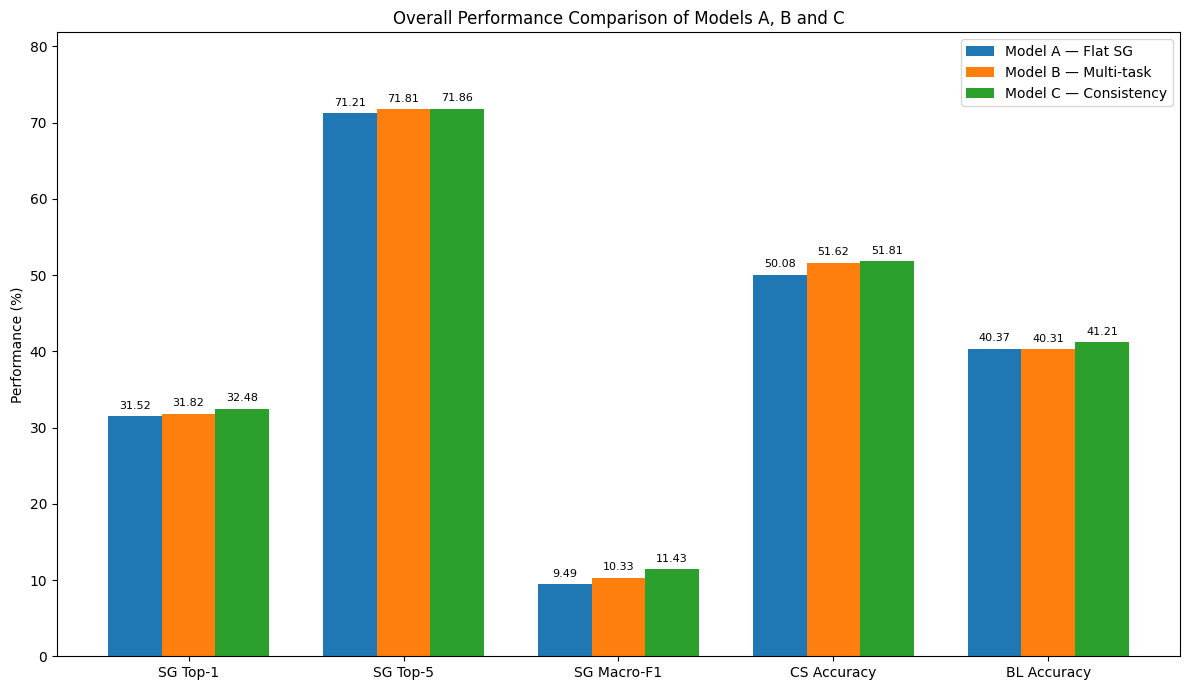

In [62]:
# ================================================================
# VISUAL 1 — OVERALL MODEL PERFORMANCE
# ================================================================

display(Markdown("## Overall Model Performance"))

comparison_data = pd.DataFrame({

    "Metric": [
        "SG Top-1",
        "SG Top-5",
        "SG Macro-F1",
        "CS Accuracy",
        "BL Accuracy"
    ],

    "Model A": [
        A_row["SG Top-1"] * 100,
        A_row["SG Top-5"] * 100,
        A_row["SG Macro-F1"] * 100,
        A_row["CS Acc."] * 100,
        A_row["BL Acc."] * 100
    ],

    "Model B": [
        B_row["SG Top-1"] * 100,
        B_row["SG Top-5"] * 100,
        B_row["SG Macro-F1"] * 100,
        B_row["CS Acc."] * 100,
        B_row["BL Acc."] * 100
    ],

    "Model C": [
        C_row["SG Top-1"] * 100,
        C_row["SG Top-5"] * 100,
        C_row["SG Macro-F1"] * 100,
        C_row["CS Acc."] * 100,
        C_row["BL Acc."] * 100
    ]
})

display(comparison_data.round(2))

x = np.arange(len(comparison_data))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 7))

barsA = ax.bar(
    x - width,
    comparison_data["Model A"],
    width,
    label="Model A — Flat SG"
)

barsB = ax.bar(
    x,
    comparison_data["Model B"],
    width,
    label="Model B — Multi-task"
)

barsC = ax.bar(
    x + width,
    comparison_data["Model C"],
    width,
    label="Model C — Consistency"
)

ax.set_ylabel("Performance (%)")
ax.set_xticks(x)
ax.set_xticklabels(comparison_data["Metric"])
ax.set_title("Overall Performance Comparison of Models A, B and C")
ax.legend()

ax.set_ylim(
    0,
    max(
        comparison_data[
            ["Model A", "Model B", "Model C"]
        ].max()
    ) + 10
)

# Numbers above bars
for bars in [barsA, barsB, barsC]:

    for bar in bars:

        value = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width()/2,
            value + 0.7,
            f"{value:.2f}",
            ha="center",
            va="bottom",
            fontsize=8
        )

plt.tight_layout()

plt.savefig(
    f"{SAVE_DIR}/01_overall_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Crystal-System Per-Class F1

,Model A,Model B,Model C
Cubic,0.646,0.708,0.706
Hexagonal,0.412,0.391,0.425
Monoclinic,0.636,0.642,0.641
Orthorhombic,0.304,0.331,0.392
Tetragonal,0.370,0.391,0.423
Triclinic,0.327,0.364,0.248
Trigonal,0.293,0.337,0.294


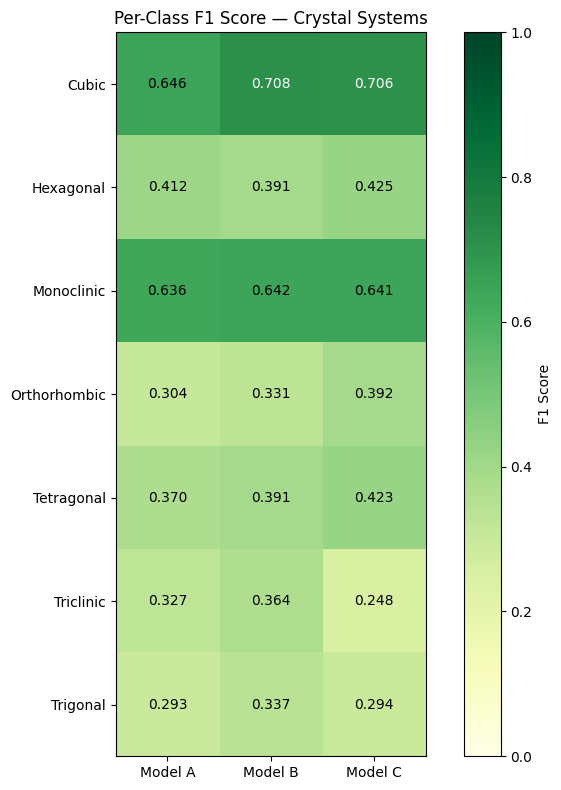

In [63]:
# ================================================================
# VISUAL 3 — PER-CLASS CRYSTAL SYSTEM F1
# ================================================================

models = {
    "Model A": A_det["pred_cs"],
    "Model B": B_det["pred_cs"],
    "Model C": C_det["pred_cs"]
}

f1_matrix = []

for model_name, pred in models.items():

    scores = f1_score(
        Y_CS,
        pred,
        labels=np.arange(len(crystal_classes)),
        average=None,
        zero_division=0
    )

    f1_matrix.append(scores)


f1_matrix = np.array(f1_matrix).T


f1_df = pd.DataFrame(
    f1_matrix,
    index=crystal_classes,
    columns=models.keys()
)

display(
    Markdown("### Crystal-System Per-Class F1")
)

display(f1_df.round(3))


fig, ax = plt.subplots(figsize=(8, 8))

im = ax.imshow(
    f1_matrix,
    cmap="YlGn",
    vmin=0,
    vmax=1
)

ax.set_xticks(
    np.arange(3)
)

ax.set_xticklabels(
    ["Model A", "Model B", "Model C"]
)

ax.set_yticks(
    np.arange(len(crystal_classes))
)

ax.set_yticklabels(
    crystal_classes
)

ax.set_title(
    "Per-Class F1 Score — Crystal Systems"
)


for i in range(f1_matrix.shape[0]):

    for j in range(f1_matrix.shape[1]):

        v = f1_matrix[i, j]

        ax.text(
            j,
            i,
            f"{v:.3f}",
            ha="center",
            va="center",
            fontsize=10,
            color="white" if v > 0.65 else "black"
        )


plt.colorbar(
    im,
    ax=ax,
    label="F1 Score"
)

plt.tight_layout()

plt.savefig(
    f"{SAVE_DIR}/03_CS_perclass_F1_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,Crystal System,Model B F1,Model C F1,ΔF1 (C-B)
0,Cubic,0.7079,0.7060,-0.0019
1,Hexagonal,0.3911,0.4250,0.0339
2,Monoclinic,0.6424,0.6411,-0.0013
3,Orthorhombic,0.3307,0.3925,0.0618
4,Tetragonal,0.3909,0.4227,0.0318
5,Triclinic,0.3645,0.2480,-0.1165
6,Trigonal,0.3371,0.2944,-0.0427


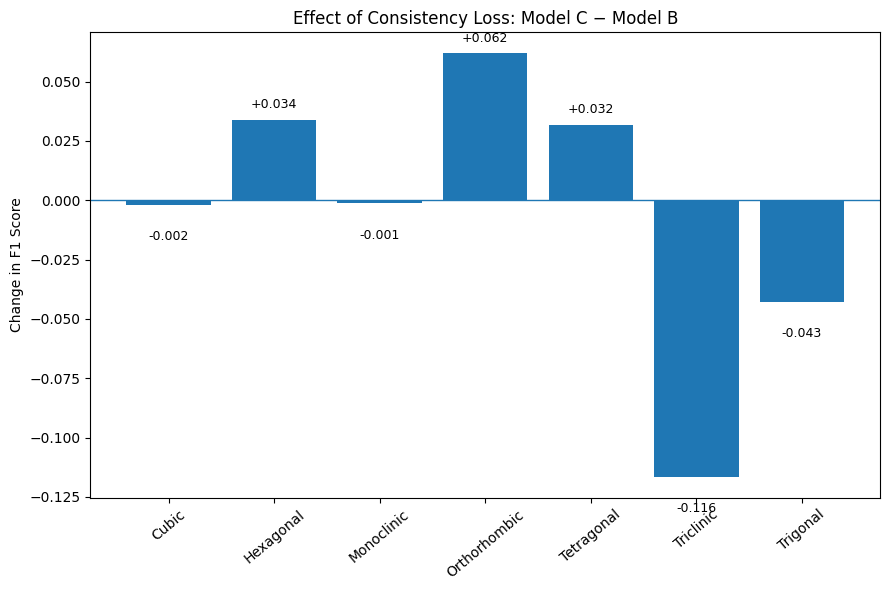

In [64]:
# ================================================================
# VISUAL 4 — MODEL C MINUS MODEL B
# ================================================================

f1_B = f1_score(
    Y_CS,
    B_det["pred_cs"],
    labels=np.arange(len(crystal_classes)),
    average=None,
    zero_division=0
)

f1_C = f1_score(
    Y_CS,
    C_det["pred_cs"],
    labels=np.arange(len(crystal_classes)),
    average=None,
    zero_division=0
)


delta_f1 = f1_C - f1_B


delta_df = pd.DataFrame({

    "Crystal System": crystal_classes,

    "Model B F1": f1_B,

    "Model C F1": f1_C,

    "ΔF1 (C-B)": delta_f1
})

display(delta_df.round(4))


fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(
    crystal_classes,
    delta_f1
)

ax.axhline(
    0,
    linewidth=1
)

ax.set_ylabel(
    "Change in F1 Score"
)

ax.set_title(
    "Effect of Consistency Loss: Model C − Model B"
)

ax.tick_params(
    axis="x",
    rotation=40
)


for bar, value in zip(
    bars,
    delta_f1
):

    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + (
            0.005 if value >= 0 else -0.015
        ),
        f"{value:+.3f}",
        ha="center",
        fontsize=9
    )


plt.tight_layout()

plt.savefig(
    f"{SAVE_DIR}/04_CS_F1_improvement_C_minus_B.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,Model A,Model B,Model C
aP,0.327,0.392,0.319
cF,0.628,0.670,0.686
cI,0.235,0.200,0.257
cP,0.256,0.287,0.282
hP,0.427,0.400,0.419
hR,0.248,0.312,0.279
mC,0.057,0.203,0.068
mP,0.550,0.544,0.549
oC,0.182,0.171,0.165
oF,0.036,0.000,0.000


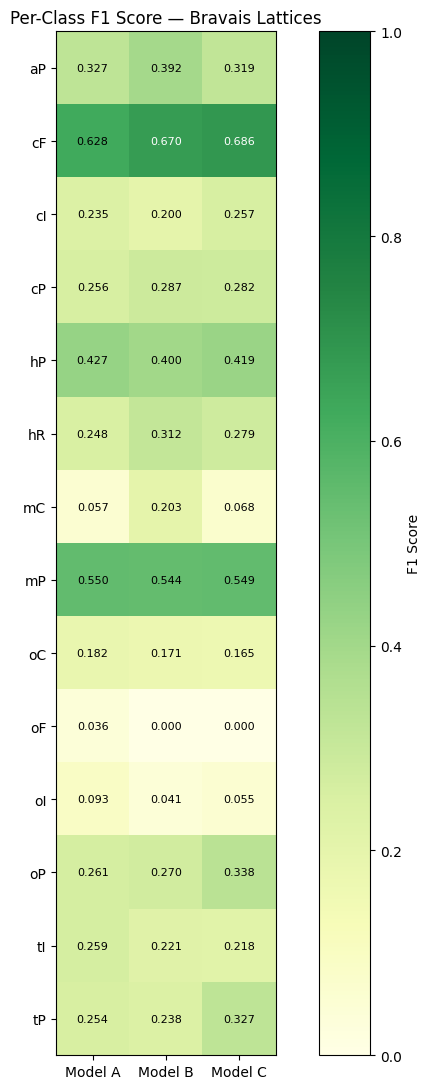

In [65]:
# ================================================================
# VISUAL 5 — BRAVAIS PER-CLASS F1
# ================================================================

BL_models = {

    "Model A":
        A_det["pred_bl"],

    "Model B":
        B_det["pred_bl"],

    "Model C":
        C_det["pred_bl"]
}


bl_f1_matrix = []

for model_name, pred in BL_models.items():

    scores = f1_score(
        Y_BL,
        pred,
        labels=np.arange(len(bravais_classes)),
        average=None,
        zero_division=0
    )

    bl_f1_matrix.append(scores)


bl_f1_matrix = np.array(
    bl_f1_matrix
).T


bl_f1_df = pd.DataFrame(
    bl_f1_matrix,
    index=bravais_classes,
    columns=BL_models.keys()
)

display(bl_f1_df.round(3))


fig, ax = plt.subplots(
    figsize=(9, 11)
)

im = ax.imshow(
    bl_f1_matrix,
    cmap="YlGn",
    vmin=0,
    vmax=1
)

ax.set_xticks(
    np.arange(3)
)

ax.set_xticklabels(
    ["Model A", "Model B", "Model C"]
)

ax.set_yticks(
    np.arange(len(bravais_classes))
)

ax.set_yticklabels(
    bravais_classes
)

ax.set_title(
    "Per-Class F1 Score — Bravais Lattices"
)


for i in range(
    bl_f1_matrix.shape[0]
):

    for j in range(
        bl_f1_matrix.shape[1]
    ):

        v = bl_f1_matrix[i, j]

        ax.text(
            j,
            i,
            f"{v:.3f}",
            ha="center",
            va="center",
            fontsize=8,
            color=(
                "white"
                if v > 0.65
                else "black"
            )
        )


plt.colorbar(
    im,
    ax=ax,
    label="F1 Score"
)

plt.tight_layout()

plt.savefig(
    f"{SAVE_DIR}/05_BL_perclass_F1_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

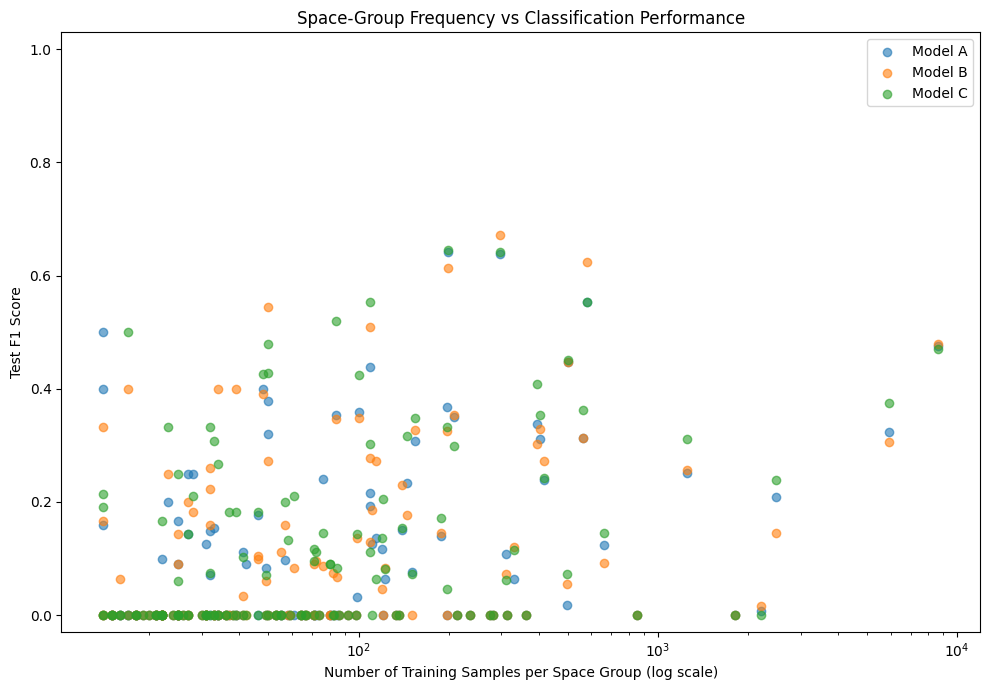

In [66]:
# ================================================================
# VISUAL 6 — SPACE GROUP FREQUENCY VS F1
# ================================================================

# Prefer training frequency
sg_train_counts = (
    train_df["sg_id"]
    .value_counts()
    .to_dict()
)


evaluated_ids = sorted(
    np.unique(Y_SG)
)


def get_sg_f1(pred):

    return f1_score(
        Y_SG,
        pred,
        labels=evaluated_ids,
        average=None,
        zero_division=0
    )


sg_f1_A = get_sg_f1(
    A_det["pred_sg"]
)

sg_f1_B = get_sg_f1(
    B_det["pred_sg"]
)

sg_f1_C = get_sg_f1(
    C_det["pred_sg"]
)


freq = np.array([
    sg_train_counts.get(
        int(sg),
        0
    )
    for sg in evaluated_ids
])


fig, ax = plt.subplots(
    figsize=(10, 7)
)


ax.scatter(
    freq,
    sg_f1_A,
    alpha=0.60,
    label="Model A"
)

ax.scatter(
    freq,
    sg_f1_B,
    alpha=0.60,
    label="Model B"
)

ax.scatter(
    freq,
    sg_f1_C,
    alpha=0.60,
    label="Model C"
)


ax.set_xscale("log")

ax.set_xlabel(
    "Number of Training Samples per Space Group (log scale)"
)

ax.set_ylabel(
    "Test F1 Score"
)

ax.set_ylim(
    -0.03,
    1.03
)

ax.set_title(
    "Space-Group Frequency vs Classification Performance"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    f"{SAVE_DIR}/06_SG_frequency_vs_F1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

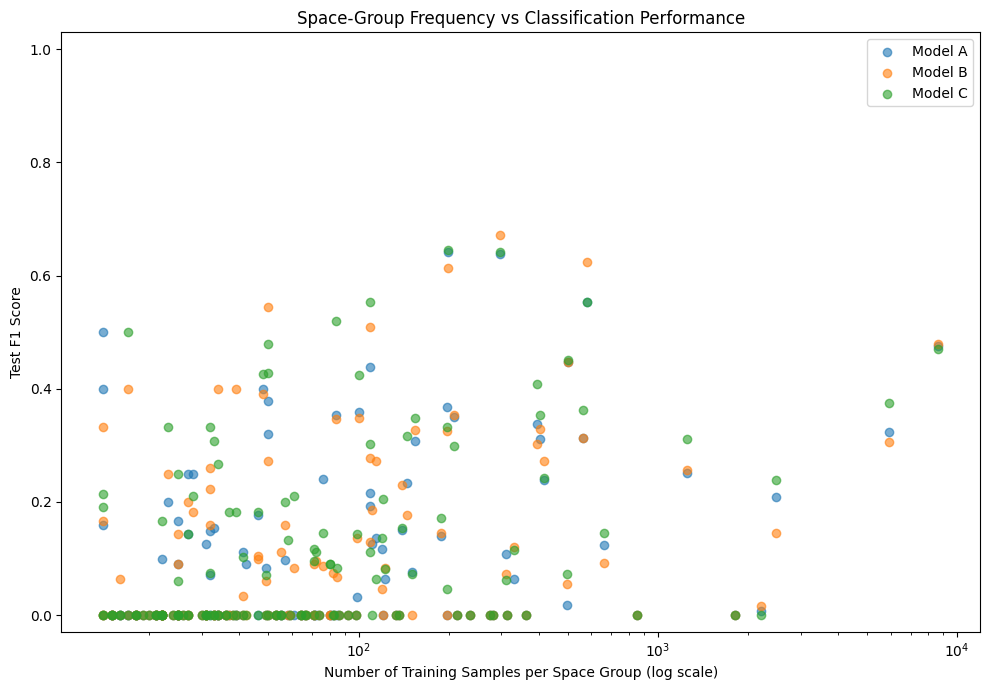

In [67]:
# ================================================================
# VISUAL 6 — SPACE GROUP FREQUENCY VS F1
# ================================================================

# Prefer training frequency
sg_train_counts = (
    train_df["sg_id"]
    .value_counts()
    .to_dict()
)


evaluated_ids = sorted(
    np.unique(Y_SG)
)


def get_sg_f1(pred):

    return f1_score(
        Y_SG,
        pred,
        labels=evaluated_ids,
        average=None,
        zero_division=0
    )


sg_f1_A = get_sg_f1(
    A_det["pred_sg"]
)

sg_f1_B = get_sg_f1(
    B_det["pred_sg"]
)

sg_f1_C = get_sg_f1(
    C_det["pred_sg"]
)


freq = np.array([
    sg_train_counts.get(
        int(sg),
        0
    )
    for sg in evaluated_ids
])


fig, ax = plt.subplots(
    figsize=(10, 7)
)


ax.scatter(
    freq,
    sg_f1_A,
    alpha=0.60,
    label="Model A"
)

ax.scatter(
    freq,
    sg_f1_B,
    alpha=0.60,
    label="Model B"
)

ax.scatter(
    freq,
    sg_f1_C,
    alpha=0.60,
    label="Model C"
)


ax.set_xscale("log")

ax.set_xlabel(
    "Number of Training Samples per Space Group (log scale)"
)

ax.set_ylabel(
    "Test F1 Score"
)

ax.set_ylim(
    -0.03,
    1.03
)

ax.set_title(
    "Space-Group Frequency vs Classification Performance"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    f"{SAVE_DIR}/06_SG_frequency_vs_F1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

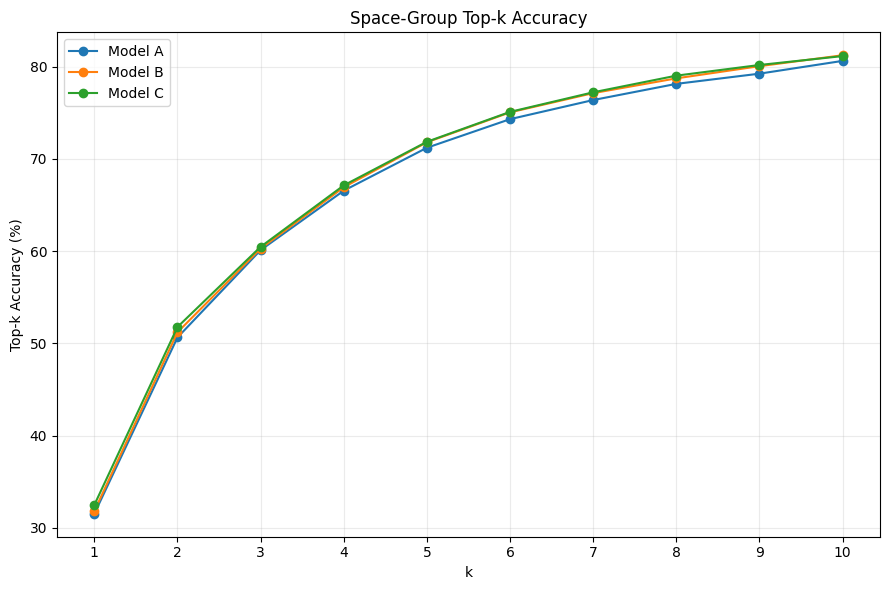

In [68]:
# ================================================================
# VISUAL 7 — TOP-K SPACE GROUP ACCURACY
# ================================================================

def top_k_accuracy(
    probs,
    y_true,
    max_k=10
):

    values = []

    order = np.argsort(
        probs,
        axis=1
    )[:, ::-1]


    for k in range(
        1,
        max_k + 1
    ):

        correct = np.any(
            order[:, :k]
            == y_true[:, None],
            axis=1
        )

        values.append(
            correct.mean() * 100
        )

    return np.array(values)


topk_A = top_k_accuracy(
    A_det["sg_probs"],
    Y_SG
)

topk_B = top_k_accuracy(
    B_det["sg_probs"],
    Y_SG
)

topk_C = top_k_accuracy(
    C_det["sg_probs"],
    Y_SG
)


k = np.arange(1, 11)


fig, ax = plt.subplots(
    figsize=(9, 6)
)

ax.plot(
    k,
    topk_A,
    marker="o",
    label="Model A"
)

ax.plot(
    k,
    topk_B,
    marker="o",
    label="Model B"
)

ax.plot(
    k,
    topk_C,
    marker="o",
    label="Model C"
)


ax.set_xticks(k)

ax.set_xlabel(
    "k"
)

ax.set_ylabel(
    "Top-k Accuracy (%)"
)

ax.set_title(
    "Space-Group Top-k Accuracy"
)

ax.grid(
    alpha=0.25
)

ax.legend()

plt.tight_layout()

plt.savefig(
    f"{SAVE_DIR}/07_SG_topk_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

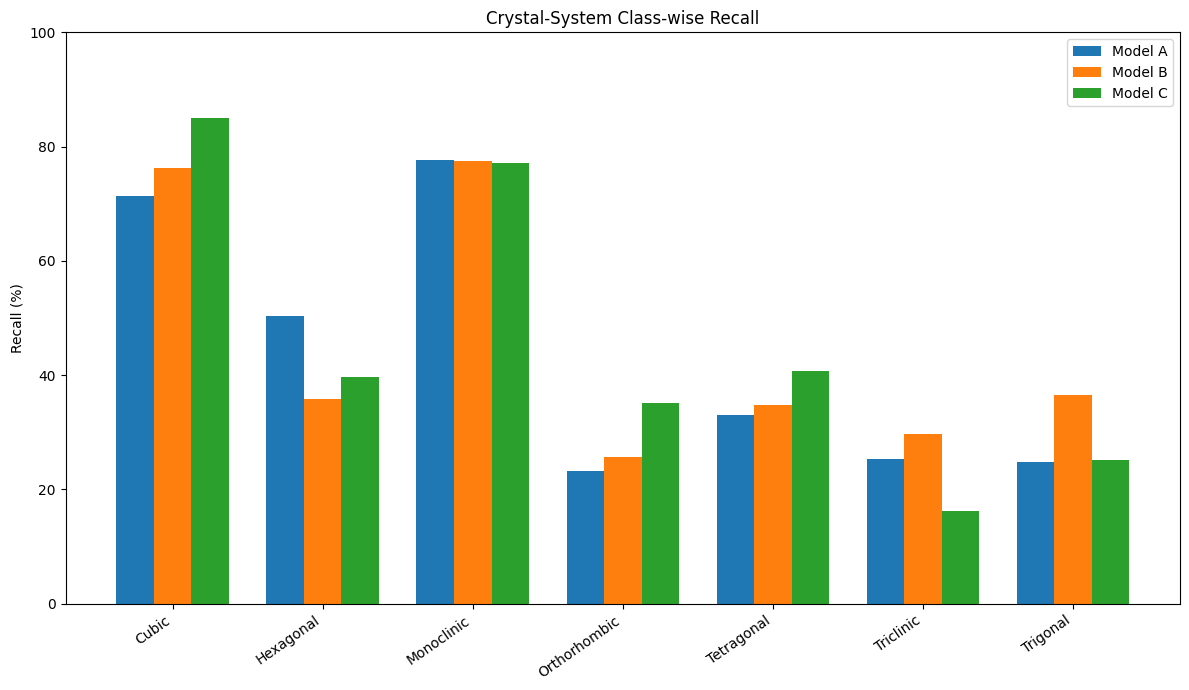

In [69]:
# ================================================================
# VISUAL 8 — CRYSTAL SYSTEM RECALL
# ================================================================

recall_A = recall_score(
    Y_CS,
    A_det["pred_cs"],
    labels=np.arange(len(crystal_classes)),
    average=None,
    zero_division=0
) * 100


recall_B = recall_score(
    Y_CS,
    B_det["pred_cs"],
    labels=np.arange(len(crystal_classes)),
    average=None,
    zero_division=0
) * 100


recall_C = recall_score(
    Y_CS,
    C_det["pred_cs"],
    labels=np.arange(len(crystal_classes)),
    average=None,
    zero_division=0
) * 100


x = np.arange(
    len(crystal_classes)
)

width = 0.25


fig, ax = plt.subplots(
    figsize=(12, 7)
)

ax.bar(
    x-width,
    recall_A,
    width,
    label="Model A"
)

ax.bar(
    x,
    recall_B,
    width,
    label="Model B"
)

ax.bar(
    x+width,
    recall_C,
    width,
    label="Model C"
)


ax.set_xticks(x)

ax.set_xticklabels(
    crystal_classes,
    rotation=35,
    ha="right"
)

ax.set_ylabel(
    "Recall (%)"
)

ax.set_ylim(
    0,
    100
)

ax.set_title(
    "Crystal-System Class-wise Recall"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    f"{SAVE_DIR}/08_CS_classwise_recall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Mean confidence — correct: 0.304
Mean confidence — incorrect: 0.2229


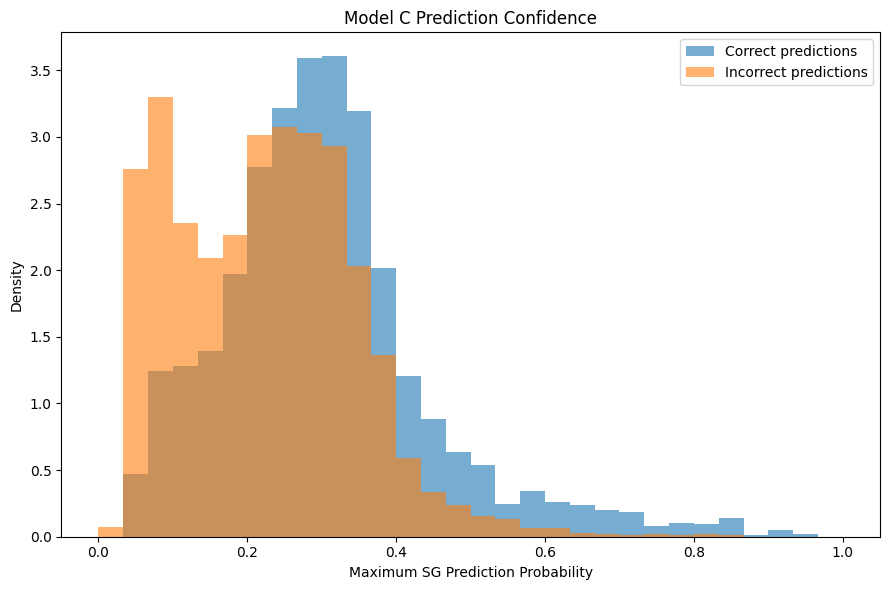

In [70]:
# ================================================================
# VISUAL 9 — MODEL C CONFIDENCE
# ================================================================

probs = C_det["sg_probs"]

pred = C_det["pred_sg"]

confidence = np.max(
    probs,
    axis=1
)

correct = (
    pred == Y_SG
)


correct_conf = confidence[
    correct
]

wrong_conf = confidence[
    ~correct
]


print(
    "Mean confidence — correct:",
    round(
        correct_conf.mean(),
        4
    )
)

print(
    "Mean confidence — incorrect:",
    round(
        wrong_conf.mean(),
        4
    )
)


fig, ax = plt.subplots(
    figsize=(9, 6)
)


bins = np.linspace(
    0,
    1,
    31
)


ax.hist(
    correct_conf,
    bins=bins,
    alpha=0.6,
    label="Correct predictions",
    density=True
)

ax.hist(
    wrong_conf,
    bins=bins,
    alpha=0.6,
    label="Incorrect predictions",
    density=True
)


ax.set_xlabel(
    "Maximum SG Prediction Probability"
)

ax.set_ylabel(
    "Density"
)

ax.set_title(
    "Model C Prediction Confidence"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    f"{SAVE_DIR}/09_Model_C_confidence_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [71]:
# ================================================================
# VISUAL 10A — FIND INTERESTING EXAMPLES
# ================================================================

A_correct = (
    A_det["pred_sg"]
    == Y_SG
)

B_correct = (
    B_det["pred_sg"]
    == Y_SG
)

C_correct = (
    C_det["pred_sg"]
    == Y_SG
)


# Cases where C is correct,
# while A or B is wrong
C_improvement_idx = np.where(

    C_correct
    &
    (
        (~A_correct)
        |
        (~B_correct)
    )

)[0]


print(
    "Cases where C corrects A/B:",
    len(C_improvement_idx)
)


# Cases all correct
all_correct_idx = np.where(
    A_correct
    &
    B_correct
    &
    C_correct
)[0]


# Cases all wrong
all_wrong_idx = np.where(
    (~A_correct)
    &
    (~B_correct)
    &
    (~C_correct)
)[0]


print(
    "All correct:",
    len(all_correct_idx)
)

print(
    "All wrong:",
    len(all_wrong_idx)
)

Cases where C corrects A/B: 553
All correct: 2002
All wrong: 4833


Detected image column: image_path


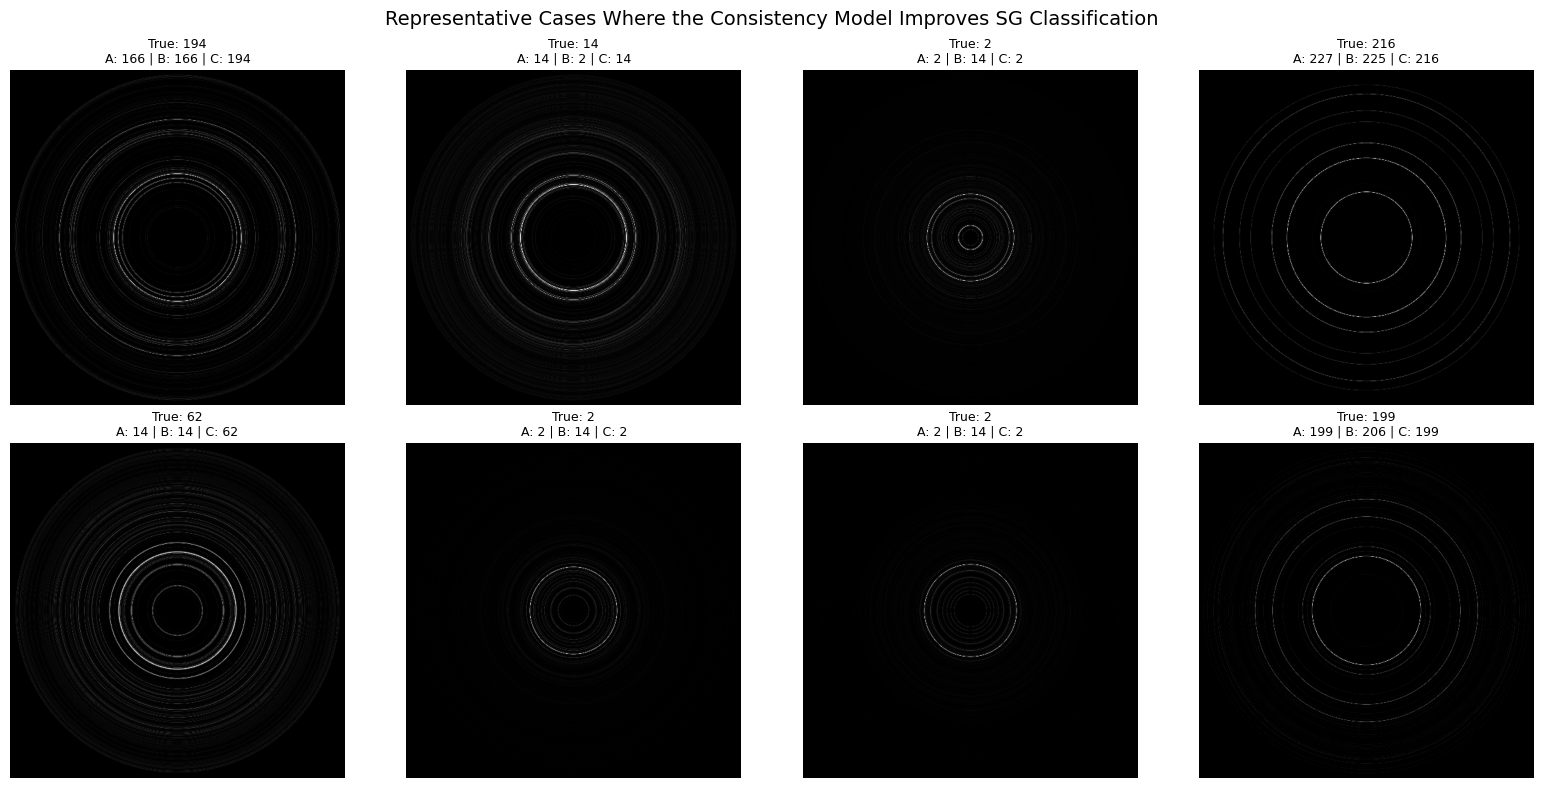

In [72]:
# ================================================================
# VISUAL 10B — REPRESENTATIVE DIFFRACTION IMAGES
# ================================================================

from PIL import Image


# Try detecting image-path column automatically
possible_cols = [

    "png_path",
    "image_path",
    "img_path",
    "path",
    "filepath"
]


IMAGE_COL = None

for c in possible_cols:

    if c in test_df.columns:

        IMAGE_COL = c
        break


print(
    "Detected image column:",
    IMAGE_COL
)


if IMAGE_COL is None:

    print(
        "⚠️ Image path column automatically nahi mila."
    )

    print(
        "Available columns:"
    )

    print(
        list(test_df.columns)
    )

else:

    sample_idx = C_improvement_idx[:8]


    fig, axes = plt.subplots(
        2,
        4,
        figsize=(16, 8)
    )

    axes = axes.flatten()


    for ax, idx in zip(
        axes,
        sample_idx
    ):

        path = test_df.iloc[idx][
            IMAGE_COL
        ]

        img = Image.open(
            path
        )

        ax.imshow(
            img,
            cmap="gray"
        )

        true_sg = id_to_sg[
            int(Y_SG[idx])
        ]

        pred_A = id_to_sg[
            int(
                A_det[
                    "pred_sg"
                ][idx]
            )
        ]

        pred_B = id_to_sg[
            int(
                B_det[
                    "pred_sg"
                ][idx]
            )
        ]

        pred_C = id_to_sg[
            int(
                C_det[
                    "pred_sg"
                ][idx]
            )
        ]


        ax.set_title(
            f"True: {true_sg}\n"
            f"A: {pred_A} | "
            f"B: {pred_B} | "
            f"C: {pred_C}",
            fontsize=9
        )

        ax.axis(
            "off"
        )


    plt.suptitle(
        "Representative Cases Where the Consistency Model Improves SG Classification",
        fontsize=14
    )

    plt.tight_layout()

    plt.savefig(
        f"{SAVE_DIR}/10_representative_C_improvements.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

### Largest improvements in Model C

,Space Group,Train Samples,F1 Model B,F1 Model C,Delta F1
107,174,33,0.000,0.308,0.308
130,216,121,0.000,0.205,0.205
52,72,37,0.000,0.182,0.182
140,230,84,0.346,0.520,0.174
109,182,22,0.000,0.167,0.167
64,99,50,0.273,0.429,0.156
113,189,145,0.176,0.316,0.139
125,204,58,0.000,0.133,0.133
117,193,61,0.083,0.211,0.127
95,159,25,0.143,0.250,0.107


### Largest decreases in Model C

,Space Group,Train Samples,F1 Model B,F1 Model C,Delta F1
129,215,27,0.200,0.143,-0.057
63,98,16,0.065,0.000,-0.065
135,223,50,0.545,0.480,-0.065
138,227,582,0.623,0.554,-0.070
106,173,82,0.074,0.000,-0.074
60,88,140,0.231,0.154,-0.077
127,206,32,0.160,0.074,-0.086
71,122,46,0.100,0.000,-0.100
139,229,55,0.111,0.000,-0.111
73,124,14,0.333,0.214,-0.119


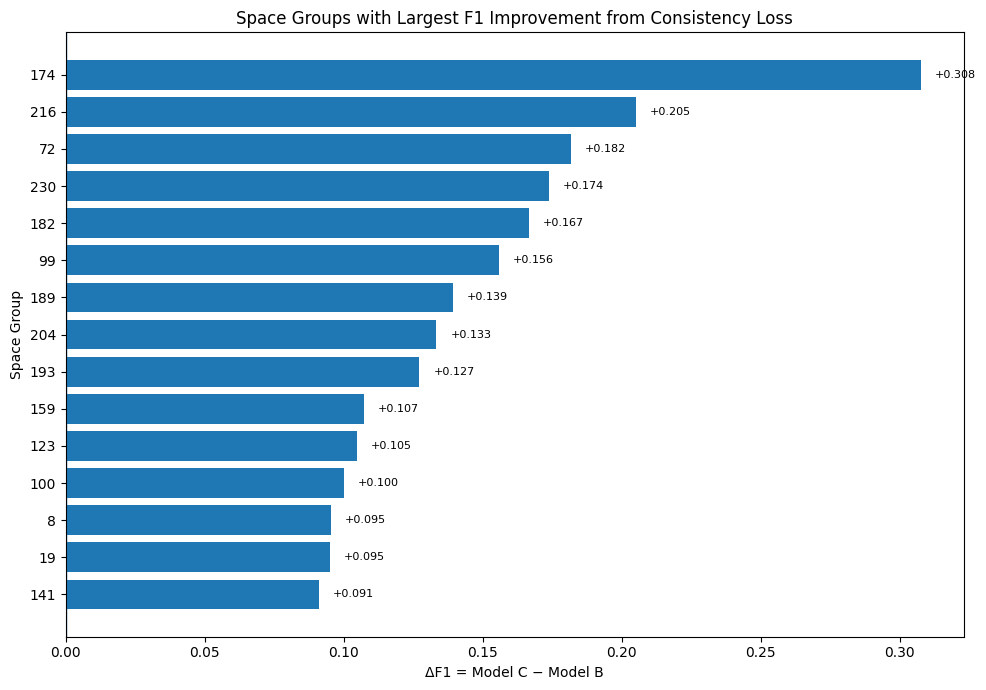

In [73]:
# ================================================================
# VISUAL 11 — SG F1 CHANGE C VS B
# ================================================================

delta_sg = (
    sg_f1_C
    -
    sg_f1_B
)


sg_names = [
    str(
        id_to_sg[
            int(x)
        ]
    )
    for x in evaluated_ids
]


delta_sg_df = pd.DataFrame({

    "Space Group": sg_names,

    "Train Samples": freq,

    "F1 Model B": sg_f1_B,

    "F1 Model C": sg_f1_C,

    "Delta F1": delta_sg

})


delta_sorted = (
    delta_sg_df
    .sort_values(
        "Delta F1",
        ascending=False
    )
)


display(
    Markdown(
        "### Largest improvements in Model C"
    )
)

display(
    delta_sorted.head(15).round(3)
)


display(
    Markdown(
        "### Largest decreases in Model C"
    )
)

display(
    delta_sorted.tail(15).round(3)
)


top_improved = (
    delta_sorted
    .head(15)
    .sort_values(
        "Delta F1"
    )
)


fig, ax = plt.subplots(
    figsize=(10, 7)
)


bars = ax.barh(
    top_improved[
        "Space Group"
    ],

    top_improved[
        "Delta F1"
    ]
)


ax.axvline(
    0,
    linewidth=1
)

ax.set_xlabel(
    "ΔF1 = Model C − Model B"
)

ax.set_ylabel(
    "Space Group"
)

ax.set_title(
    "Space Groups with Largest F1 Improvement from Consistency Loss"
)


for bar, value in zip(
    bars,
    top_improved[
        "Delta F1"
    ]
):

    ax.text(
        value + 0.005,
        bar.get_y()
        + bar.get_height()/2,
        f"{value:+.3f}",
        va="center",
        fontsize=8
    )


plt.tight_layout()

plt.savefig(
    f"{SAVE_DIR}/11_SG_largest_F1_improvements.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,Frequency Group,A_F1,B_F1,C_F1
0,Rare (≤50),0.063,0.069,0.074
1,Medium (51–200),0.091,0.105,0.126
2,Frequent (>200),0.191,0.194,0.204


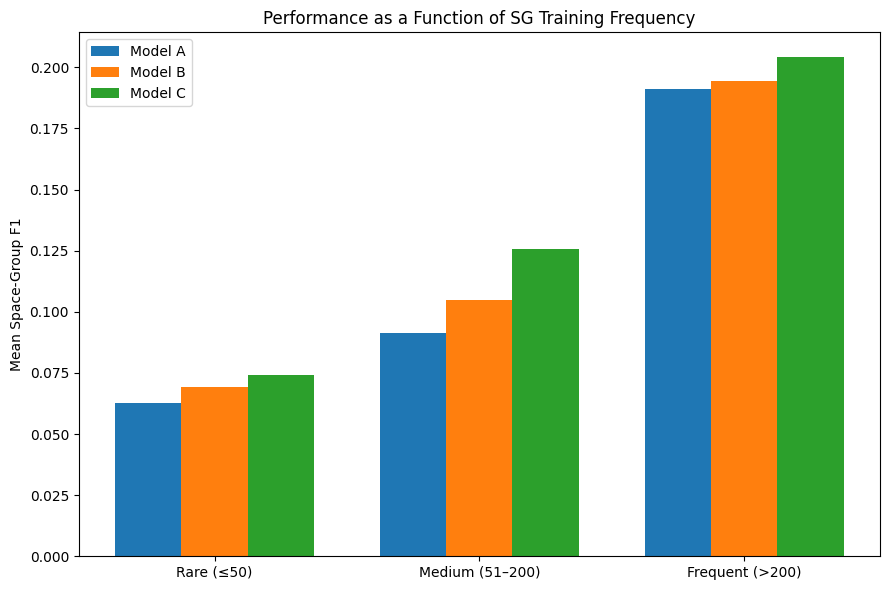

In [74]:
# ================================================================
# VISUAL 12 — PERFORMANCE BY CLASS FREQUENCY
# ================================================================

frequency_df = pd.DataFrame({

    "sg_id": evaluated_ids,

    "frequency": freq,

    "A_F1": sg_f1_A,

    "B_F1": sg_f1_B,

    "C_F1": sg_f1_C
})


frequency_df[
    "Frequency Group"
] = pd.cut(

    frequency_df[
        "frequency"
    ],

    bins=[
        -1,
        50,
        200,
        np.inf
    ],

    labels=[
        "Rare (≤50)",
        "Medium (51–200)",
        "Frequent (>200)"
    ]
)


frequency_summary = (

    frequency_df

    .groupby(
        "Frequency Group",
        observed=False
    )[
        [
            "A_F1",
            "B_F1",
            "C_F1"
        ]
    ]

    .mean()

    .reset_index()
)


display(
    frequency_summary.round(3)
)


x = np.arange(
    len(
        frequency_summary
    )
)

width = 0.25


fig, ax = plt.subplots(
    figsize=(9, 6)
)


ax.bar(
    x-width,
    frequency_summary[
        "A_F1"
    ],
    width,
    label="Model A"
)

ax.bar(
    x,
    frequency_summary[
        "B_F1"
    ],
    width,
    label="Model B"
)

ax.bar(
    x+width,
    frequency_summary[
        "C_F1"
    ],
    width,
    label="Model C"
)


ax.set_xticks(x)

ax.set_xticklabels(
    frequency_summary[
        "Frequency Group"
    ]
)

ax.set_ylabel(
    "Mean Space-Group F1"
)

ax.set_title(
    "Performance as a Function of SG Training Frequency"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    f"{SAVE_DIR}/12_frequency_group_F1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()